# Predicting which coding bans a new AI model obeys

**The question.** Tell a code model *"Do not use depth-first search"* and it should write something else, but often it does not. Can we predict **which bans a model will obey before showing it any ban**? This experiment tests a *ban-free random-push screen* on a model family that was not used to build it: **`google/gemma-3-4b-it`** (bf16, one 16 GB GPU).

**The screen (Claim 3a).**
1. For each of 15 coding tasks the model writes 50 programs for a *neutral twin* prompt. This is the ban prompt with the banned algorithm's name replaced by a meaningless noun, at the same token length. Its modal correct algorithm is the **default D**.
2. Eight fixed random directions × α ∈ {1, 2} are added to the residual stream at the **task-spec tokens** of blocks 11–22 (the middle third of 34), during the prompt prefill only.
3. A direction **escapes** if it moves the model off D (off-default share − p0 ≥ 0.20) without costing pass rate (≥ 0.8 × the twin's). The escape is then confirmed at N = 30 with an exact binomial test.
4. `E_t` is the share of the 8 directions that escape. **MOVABLE (`E_t > 0`) predicts that the model obeys a ban of D**: `A_t ≥ 0.5`, where `A_t` is the share of 100 ban programs that use another catalogue algorithm.

All 15 predictions and this analysis code were **sha256 hash-committed before any ban prompt was built**. Then 1,500 modal-ban programs were generated and labelled (10,730 programs in all). The same sampling also gives:
- **C3b**, landing forecasts: *which* algorithm the model switches to;
- **C1**, the price of diversity: plan noise vs **temperature** vs a novelty instruction as creativity knobs.

**What this notebook runs.** Generation needs the gated Gemma weights and a GPU (1.28 GPU-hours), so the notebook re-runs the **CPU analysis stages** of `method.py` on the 15 stored task-level events (`mini_demo_data.json`):

| Code | Section |
|---|---|
| the **frozen, pre-registered analysis** `predictions/analysis_c3.py` (verbatim) | 3 |
| C3a + sensitivities, rivals, C3b and C1 (`src/final_analysis.py`) | 5–8 |
| the post-hoc T2 re-audit (`src/posthoc_t2.py`) | 9 |
| the independent re-derivation and placebos (`audit/rederive.py`) | 10 |
| every number vs the experiment's reported value, and six figures | 11 |

**Reported headline.**
- Movable tasks: T1, T2, T04, T05, T10, T11. Observed to obey: T1, T2, T03, T05.
- **C3a is INCONCLUSIVE:** BA 0.739 (95% CI [0.40, 0.95]), Fisher p 0.235, Spearman ρ 0.537 (one-sided permutation p 0.025).
- The novelty instruction predicts compliance better (ρ 0.77).
- Plan noise raises algorithmic diversity at ≤ 5 pass points where temperature 1.3/1.6 does not.
- **Key caveat:** the frozen T2 labeller reads array-based Dijkstra as Bellman-Ford.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (the driver and the analysis stages log with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# ---- method.py (pipeline driver)
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# ---- predictions/analysis_c3.py (frozen analysis), src/final_analysis.py, src/posthoc_t2.py, audit/rederive.py
import collections
import importlib.util
import itertools
import json
import math
import re
from typing import Any

import numpy as np
from scipy import stats

# ---- notebook additions: tables and figures
import types

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-4/experiment-23/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
task_events = data["datasets"][0]["examples"]
print(data["metadata"]["dataset_source"])
print(f"{len(task_events)} task events: {', '.join(ex['metadata_task'] for ex in task_events)}")
print(f"model: {data['metadata']['model']} @ {data['metadata']['revision'][:12]}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
full_method_out.json -> datasets['heldout_task_events'] (15 of 15 examples)
15 task events: T1, T2, T03, T04, T06, T05, T10, R1, T08, R3, T13, R6, T14, T11, R2
model: google/gemma-3-4b-it @ 093f9f388b31


## Configuration

The analysis parameters below control **only Monte-Carlo resampling**: permutation tests, bootstraps, placebos and rarefaction. The point estimates do not depend on them:
- `E_t`, `A_t`, BA, the Fisher table and p, Spearman ρ, Kendall τ;
- the rival ρs, the C3b log scores, the C1 hull values.

Larger counts tighten the permutation p-values, intervals and placebo rates. The notebook uses the **original counts**: with the code's fixed seeds they reproduce the reported values, and the whole notebook runs in about 35 s on 2 CPU cores. Lower them for a quicker pass; the smallest values that still produce every output are about 10 permutations or bootstraps and 2 placebo replicates.

`RUN_FULL_PIPELINE` switches on the original GPU pipeline of `method.py`. It needs:
- a checkout of the experiment folder (`ARTIFACT_DIR`) with its `pyproject.toml` environment;
- a 16 GB GPU;
- `HF_TOKEN` with access to the gated `google/gemma-3-4b-it`;
- an OpenRouter key.

`PIPELINE_FROM = "analysis"` re-runs only the CPU stages on the stored samples.

In [5]:
# ---- frozen analysis (predictions/analysis_c3.py): the primary C3a test and the rival bootstrap
N_PERM = 100_000         # permutations for the exact-permutation Spearman p          (original: 100_000)
N_BOOT = 2_000           # task-bootstrap replicates for the BA / rho CIs and rivals  (original: 2_000)
# ---- src/final_analysis.py and src/posthoc_t2.py: sensitivities, continuous predictor, post-hoc re-run
SENS_N_PERM = 20_000     # (original: 20_000)
SENS_N_BOOT = 1_000      # (original: 1_000)
# ---- src/final_analysis.py: C1 prices
C1_RAREFY_N_SUB = 1_000  # rarefaction subsamples for each arm's Hill-1 at depth 25   (original: 1_000)
C1_BOOT = 100            # bootstrap replicates for the H5 interval                    (original: 100)
# ---- audit/rederive.py: independent permutation loop and placebos
REDERIVE_PERM_N = 20_000 # permutations for the re-derived one-sided Spearman p       (original: 20_000)
N_SHUFFLE = 1_000        # shuffled-outcome placebo replicates                         (original: 1_000)
N_RANDOM_PRED = 300      # random-predictor placebo replicates                         (original: 300)
PLACEBO_PERM_N = 300     # permutations inside each placebo test                       (original: 300)

# ---- the original GPU pipeline (method.py); off in the demo
RUN_FULL_PIPELINE = False  # True runs method.py's stages: needs the experiment folder with its pyproject.toml environment,
                           # a 16 GB GPU, HF_TOKEN with access to google/gemma-3-4b-it and OPENROUTER_API_KEY
ARTIFACT_DIR = "."         # the experiment folder of the published repository (holds method.py, src/, data/)
PIPELINE_FROM = "analysis" # first stage of the full run: 'analysis' re-analyses the stored samples on a CPU,
                           # 'inputs' regenerates everything (about 2 GPU-hours on an RTX 2000 Ada)

## 1. The pipeline driver (`method.py`)

`method.py` runs one module of `src/` per stage, in order: `--from <stage>` resumes, `--only <stage>` runs a single stage. From `pilot` to `bans` a background label worker labels every generated program:
- runtime tracing first, then AST rules;
- a blind LLM judge only when those two disagree.

| Stage | What it does | Needs |
|---|---|---|
| `inputs`, `screen` | stage the frozen upstream inputs (sha256-checked); recompute the iteration-3 Qwen screen | CPU |
| `qwen`, `gputests`, `probe` | Qwen3-8B ban-to-residual ratio (sets the push unit), engine tests, unit calibration probe | GPU |
| `pilot`, `commit1`, `phaseA`, `afterA` | ban-free generation (below), then **commit #1** | GPU |
| `commit2` | grep audit + pre-ban predictions + hash of the frozen analysis (**commit #2, before any ban prompt**) | CPU |
| `bans` | 1,500 modal-ban programs (5 templates × 20 CRN slots × 15 tasks) + extras | GPU |
| `audit` | blind label audit and novelty audit | OpenRouter |
| **`analysis`** | C3a, rivals, C3b, C1 with the frozen code; commit #3 | **CPU: sections 4–8 below** |
| **`posthoc`** | T2 mechanism re-audit and C3a re-run | OpenRouter: **section 9 re-runs the C3a part** |
| `figures`, `tests`, **`rederive`**, `bookkeeping`, `outputs` | figures, CPU tests, **independent re-derivation (section 10)**, outputs | CPU |

The ban-free generation (pilot to afterA) covers:
- the twin (N = 50);
- the 8 directions × α ∈ {1, 2};
- plan noise and temperature 1.3;
- the novelty instruction;
- "can" attempts;
- the opening ladder.

The cell below is the original driver. With `RUN_FULL_PIPELINE = False` it only lists the stages. Notebook changes are marked `# notebook:`:
- `ROOT` comes from the config;
- the log-file sink is created only for a real run;
- `--from` is taken from `PIPELINE_FROM`.

In [6]:
"""Predicting which bans a new model obeys -- held-out-family (gemma-3-4b-it) confirmation of Claim 3a.

Method (ours): a ban-free push screen. Eight fixed isotropic directions x alpha {1, 2} are written into the task-spec
states of the middle third of blocks (displacement-targeted, ban-free unit transferred from Qwen3-8B) on the
token-matched neutral twin prompt; a direction 'escapes' if it moves the model off its default algorithm without a
pass-rate cost (stage 1, N = 10) and survives a 20-sample confirmation with an exact binomial gate (N = 30).
E_t = share of escaping directions; MOVABLE = E_t > 0 predicts that the model will OBEY a ban of its default.
Baselines / rivals (same pipeline, same CRN slots): the un-pushed twin (zero dose), fresh-direction plan noise at
alpha 1 and 2, temperature 1.3, the novelty instruction (prompting ceiling), forced 'can' attempts, the twin's modal
share (how collapsed the default is), the opening-ladder margin; landing forecasts: push-landing, opening ladder,
association, AST proximity. All predictions are hash-committed (commit #2) before any ban prompt is built.

Pipeline (each stage is a module under src/; this driver runs them in order, resumable with --from):
  inputs     src/stage_inputs.py   stage inputs, sha256 checks, labeller re-check, dependency extraction
  screen     src/screen.py         iteration-3 screen file (shared protocol) + T5 reproduction
  qwen       src/qwen_ratio.py     Qwen3-8B ban-to-residual ratio r_Q (plain and outlier-excluded) + positive control
  gputests   src/gpu_tests.py      U1-U4, U6 on gemma
  probe      src/unit_probe.py     unit calibration probe (diagnostic; decided deviation D3)
  pilot      src/banfree.py pilot + commit1   pilot, default rule, cap rule, commit #1
  phaseA     src/banfree.py phaseA            twin N=50, escape stage 1, PN alpha 1/2, T 1.3 (CRN, B = 36)
  afterA     src/banfree.py all_after_A       confirmation top-up, association, opening ladder, novelty, 'can'
             (optional T 1.6 cell: src/banfree.py t16 --tasks <movable tasks>, run after the bans)
  commit2    src/commit2.py        grep audit + pre-ban predictions + frozen analysis hash (commit #2)
  bans       src/bans.py           1,500 modal-ban programs (+ extras) and the ban-derived unit
  audit      src/judge_audit.py    label audit, disagreement rates, novelty audit (OpenRouter, capped)
  analysis   src/final_analysis.py C3a, rivals, C3b, C1 prices, commit #3
  posthoc    src/posthoc_t2.py     POST HOC mechanism re-audit of T2 'bf_spfa' labels (array-Dijkstra), C3a re-run
  figures    src/figures.py
  tests      src/tests_cpu.py      CPU tests T1-T6
  rederive   audit/rederive.py     independent re-derivation of the headline numbers
  bookkeeping src/bookkeeping.py   timing summary and deviations log
  outputs    src/outputs.py        data/samples.jsonl, method_out.json (+ mini / preview)
The label worker (src/label_worker.py) runs in the background from 'pilot' to 'bans' and labels every raw row.
"""

ROOT = Path(ARTIFACT_DIR).resolve()  # notebook: original is Path(__file__).resolve().parent
PY = sys.executable
STAGES = [
    ("inputs", ["src/stage_inputs.py"]),
    ("screen", ["src/screen.py"]),
    ("qwen", ["src/qwen_ratio.py"]),
    ("gputests", ["src/gpu_tests.py"]),
    ("probe", ["src/unit_probe.py"]),
    ("pilot", ["src/banfree.py", "pilot"]),
    ("commit1", ["src/banfree.py", "commit1"]),
    ("phaseA", ["src/banfree.py", "phaseA"]),
    ("afterA", ["src/banfree.py", "all_after_A"]),
    ("commit2", ["src/commit2.py"]),
    ("bans", ["src/bans.py"]),
    ("audit", ["src/judge_audit.py"]),
    ("analysis", ["src/final_analysis.py"]),
    ("posthoc", ["src/posthoc_t2.py"]),
    ("figures", ["src/figures.py"]),
    ("tests", ["src/tests_cpu.py"]),
    ("rederive", ["audit/rederive.py"]),
    ("bookkeeping", ["src/bookkeeping.py"]),
    ("outputs", ["src/outputs.py"]),
]
WAIT_BEFORE = {"commit1": ["raw_pilot.jsonl"], "afterA": ["raw_phaseA.jsonl"],
               "commit2": ["raw_phaseA.jsonl", "raw_phaseB.jsonl", "raw_novelty.jsonl", "raw_can.jsonl"],
               "audit": ["raw_bans.jsonl"], "analysis": ["raw_bans.jsonl"]}

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
if RUN_FULL_PIPELINE:  # notebook: the log-file sink is only created for a real pipeline run
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"running {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(cmd)}")
    logger.info(f"done {' '.join(cmd)} in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    names = [s for s, _ in STAGES]
    start = names[0]
    only = None
    if "--from" in sys.argv:
        start = sys.argv[sys.argv.index("--from") + 1]
    if "--only" in sys.argv:
        only = sys.argv[sys.argv.index("--only") + 1]
    labeller = None
    try:
        for name, cmd in STAGES[names.index(start):]:
            if only and name != only:
                continue
            if name == "pilot" and labeller is None:
                labeller = subprocess.Popen([PY, "src/label_worker.py"], cwd=ROOT,
                                            stdout=open(ROOT / "logs" / "label_worker.out", "a"),
                                            stderr=subprocess.STDOUT)
                logger.info(f"label worker started (pid {labeller.pid})")
            if name in WAIT_BEFORE and labeller is not None:
                run(["src/wait_labels.py"] + WAIT_BEFORE[name])
            run(cmd)
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=600)
            (ROOT / "data" / "STOP_LABELLER").unlink(missing_ok=True)


if RUN_FULL_PIPELINE:  # notebook: original is `if __name__ == "__main__": main()` with --from / --only on the command line
    sys.argv = ["method.py", "--from", PIPELINE_FROM]
    main()
else:
    print(f"RUN_FULL_PIPELINE = False: the {len(STAGES)} stages are listed, not run")
    for name, cmd in STAGES:
        print(f"  {name:<12} {' '.join(cmd)}")

RUN_FULL_PIPELINE = False: the 19 stages are listed, not run
  inputs       src/stage_inputs.py
  screen       src/screen.py
  qwen         src/qwen_ratio.py
  gputests     src/gpu_tests.py
  probe        src/unit_probe.py
  pilot        src/banfree.py pilot
  commit1      src/banfree.py commit1
  phaseA       src/banfree.py phaseA
  afterA       src/banfree.py all_after_A
  commit2      src/commit2.py
  bans         src/bans.py
  audit        src/judge_audit.py
  analysis     src/final_analysis.py
  posthoc      src/posthoc_t2.py
  figures      src/figures.py
  tests        src/tests_cpu.py
  rederive     audit/rederive.py
  bookkeeping  src/bookkeeping.py
  outputs      src/outputs.py


## 2. Shared constants (`src/cfg.py`)

These are the task ids, the five ban / neutral-twin templates and the design constants of the escape rule, copied from `src/cfg.py`.
- **T1** (grid path search) and **T2** (weighted shortest path) are the path-search tasks of the iteration-2 suite.
- The other 13 tasks come from the frozen coding bench.

Each ban prompt `{X}` names the model's default algorithm. Its **neutral twin** puts a meaningless noun `{N}` in the same frame and pads it with ` .` to the same token length. Twin and ban differ only in the banned name, and every arm reuses the same common-random-number uniforms per (task, template, slot).

In [7]:
# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH12 = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
BENCH_TASKS = BENCH12 + ("R2",)
ALL_TASKS = PATH_TASKS + BENCH_TASKS      # 15 tasks
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."

# ------------------------------------------------------------------------------------------------ design
ESCAPE_SEEDS = tuple(range(9001, 9009))   # 8 fixed isotropic directions
ALPHAS = (1.0, 2.0)
T_HOT = 1.3
N_TWIN_PER_T = 10                          # twin slots 0-9 per template (N = 50 per task)
N_STAGE1_PER_T = 2                         # escape stage 1: slots 0-1 per template (N = 10 per direction-alpha)
STAGE2_SLOTS = (2, 3, 4, 5)                # confirmation top-up (N = 20 more)
N_BAN_PER_T = 20                           # ban slots 0-19 per template (N = 100 per task, primary)
ESCAPE_EXCESS = 0.20
ESCAPE_PASS_FRAC = 0.80
BINOM_ALPHA = 0.05
P0_FLOOR = 0.01
COMPLY_THRESH = 0.5

TASK_TITLES = data["metadata"]["task_titles"]  # notebook: readable task names for tables and figures
print(", ".join(f"{t} = {TASK_TITLES[t]}" for t in ALL_TASKS))

T1 = grid path search, T2 = weighted shortest path, T03 = k-th smallest, T04 = substring search, T06 = find duplicate, T05 = two-sum, T10 = connected components, R1 = non-overlapping intervals, T08 = fibonacci, R3 = topological order, T13 = merge intervals, R6 = first/last position, T14 = top-k frequent, T11 = longest increasing subsequence, R2 = cycle detection


## 3. The frozen analysis (`predictions/analysis_c3.py`)

This module was **hash-committed (sha256, commit #2 in `commitments.log`) together with every per-task prediction, before any ban prompt was built**. It is copied here verbatim and split at its own section markers. The only change: its two module constants `N_PERM` (100,000) and `N_BOOT` (2,000) come from the config cell.

**Basic statistics:**
- **balanced accuracy**, with *obeys* (`C_t = 1`) as the positive class;
- **Fisher's exact test** on the 2×2 table *predicted obey / fail × observed obey / fail*;
- **Spearman ρ** with an exact-permutation p-value, using average ranks: 9 of the 15 tasks share `E_t = 0`;
- **Kendall τ-b.**

In [8]:
"""FROZEN ANALYSIS (hash-committed in commit #2, before any ban prompt reaches the model).

C3a (primary): per task, A_t = catalogue-only avoidance = #(ban attempts with label in catalogue minus {D}) / N_ban,
C_t = 1[A_t >= 0.5]. Prediction: MOVABLE (E_t > 0) -> predicted to obey (C_t = 1).
  BA = (TPR + TNR) / 2 with positive class C_t = 1; two-sided Fisher exact (one-sided 'greater' too); exact permutation
  Spearman(E_t, A_t) (1e5 permutations, average ranks) with Kendall tau-b beside it.
  Verdict: CONFIRMED iff BA >= 0.8 AND Fisher p < 0.05 AND rho >= 0.5; DISCONFIRMED iff BA <= 0.6; else INCONCLUSIVE.
  Edge cases: all tasks in one compliance class -> BA untestable, Spearman alone; a single predicted class -> BA 0.5
  ('no discrimination'), disconfirming only if both outcome classes exist; ties in E_t -> average ranks.
  Task bootstrap (2,000) CIs for BA and rho; task-label permutation placebo; leave-one-task-out BA and rho;
  conservative primary-family bound min(1, 3p).
Rivals: sign-oriented Spearman with A_t, paired task-bootstrap delta-rho, partial Spearman of E_t given each rival,
  BA of a median-threshold rule (reported, not optimised).
C3b: p' = 0.93 p + 0.05 uniform(survivors) + 0.02 'other'; realised = ban attempts with label not in {D, invalid,
  disputed}; mean log score per event; top-1 hit vs the modal realised catalogue landing (fractional tie credit
  separately; defined-only hit rates); contest: a ban-free forecast (push-landing or ladder) beats association by
  >= 0.10 nats on >= 3 disagreeing events; paired Wilcoxon (Holm over the two comparisons) if >= 10 disagreeing.
C1 (descriptive): correct-only rarefied Hill-1 at depth 25; pass cost = 100 x (pass_twin - pass_arm) floored at 0;
  H5 / P15 / P20 = best correct-only Hill-1 within 5 / 15 / 20 pass points on the randomisation hull of each knob
  class (mixtures twin->setting and between adjacent settings; Monte-Carlo rarefaction at depth 25).
"""

SMOOTH = {"f": 0.93, "uniform_S": 0.05, "other": 0.02}
NOT_OFF = ("invalid", "disputed")
# N_PERM = 100_000  # notebook: frozen value; N_PERM is set in the config cell
# N_BOOT = 2_000    # notebook: frozen value; N_BOOT is set in the config cell


# ------------------------------------------------------------------------------------------------ basic statistics
def rankdata(x: np.ndarray) -> np.ndarray:
    return stats.rankdata(x, method="average")


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return float("nan")
    rx, ry = rankdata(x), rankdata(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_spearman(x: np.ndarray, y: np.ndarray, n_perm: int = N_PERM, seed: int = 0) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = spearman(x, y)
    if not np.isfinite(rho):
        return {"rho": None, "p_one_sided": None, "p_two_sided": None, "n": len(x), "note": "constant input"}
    rx, ry = rankdata(x), rankdata(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    perm = np.argsort(rng.random((n_perm, len(x))), axis=1)
    rp = (rx[None, :] * ry[perm]).mean(1)
    return {"rho": rho, "p_one_sided": float((np.sum(rp >= rho - 1e-12) + 1) / (n_perm + 1)),
            "p_two_sided": float((np.sum(np.abs(rp) >= abs(rho) - 1e-12) + 1) / (n_perm + 1)), "n": len(x)}


def kendall(x, y) -> float | None:
    if len(set(x)) < 2 or len(set(y)) < 2:
        return None
    return float(stats.kendalltau(x, y, variant="b").statistic)


def balanced_accuracy(pred: list[int], obs: list[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    pos, neg = obs == 1, obs == 0
    out = {"n_pos": int(pos.sum()), "n_neg": int(neg.sum()), "n_pred_pos": int(pred.sum()),
           "n_pred_neg": int((1 - pred).sum())}
    if pos.sum() == 0 or neg.sum() == 0:
        out.update(BA=None, TPR=None, TNR=None, testable=False, note="all tasks in one compliance class")
        return out
    tpr = float((pred[pos] == 1).mean())
    tnr = float((pred[neg] == 0).mean())
    out.update(BA=(tpr + tnr) / 2, TPR=tpr, TNR=tnr, testable=True,
               single_predicted_class=bool(pred.min() == pred.max()))
    return out


def fisher(pred: list[int], obs: list[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    tab = [[int(((pred == 1) & (obs == 1)).sum()), int(((pred == 1) & (obs == 0)).sum())],
           [int(((pred == 0) & (obs == 1)).sum()), int(((pred == 0) & (obs == 0)).sum())]]
    if (pred.min() == pred.max()) or (obs.min() == obs.max()):
        return {"table": tab, "p_two_sided": 1.0, "p_greater": 1.0, "note": "degenerate margin"}
    return {"table": tab, "p_two_sided": float(stats.fisher_exact(tab, alternative="two-sided").pvalue),
            "p_greater": float(stats.fisher_exact(tab, alternative="greater").pvalue)}

### C3a: the pre-registered test

`c3a()` scores the committed movability prediction against the observed compliance class `C_t = 1[A_t ≥ 0.5]`. The decision rule was committed before any ban:
- **CONFIRMED** iff BA ≥ 0.8 **and** Fisher p < 0.05 **and** ρ ≥ 0.5;
- **DISCONFIRMED** iff BA ≤ 0.6;
- **INCONCLUSIVE** otherwise.

It also reports:
- a task bootstrap (`n_boot`) for the BA and ρ intervals;
- a 2,000-draw task-label permutation placebo;
- leave-one-task-out BA and ρ;
- the conservative family bound min(1, 3p).

In [9]:
# ------------------------------------------------------------------------------------------------ C3a
def c3a(tasks: list[str], E: dict[str, float], A: dict[str, float], movable: dict[str, bool] | None = None,
        thresh: float = 0.5, seed: int = 0, n_perm: int = N_PERM, n_boot: int = N_BOOT) -> dict[str, Any]:
    tasks = [t for t in tasks if t in E and t in A and E[t] is not None and A[t] is not None]
    e = np.array([E[t] for t in tasks], float)
    a = np.array([A[t] for t in tasks], float)
    mv = np.array([int((movable or {}).get(t, E[t] > 0)) for t in tasks])
    C = (a >= thresh).astype(int)
    ba = balanced_accuracy(mv, C)
    fi = fisher(mv, C)
    sp = perm_spearman(e, a, n_perm=n_perm, seed=seed)
    kt = kendall(list(e), list(a))
    rho = sp["rho"]
    if not ba["testable"]:
        verdict = "UNTESTABLE_BA (Spearman alone)"
        if rho is not None:
            verdict += f": rho={rho:.3f}"
    else:
        b = ba["BA"]
        if b >= 0.8 and fi["p_two_sided"] < 0.05 and rho is not None and rho >= 0.5:
            verdict = "CONFIRMED"
        elif b <= 0.6:
            verdict = "DISCONFIRMED"
        else:
            verdict = "INCONCLUSIVE"
    rng = np.random.default_rng(seed + 1)
    bb, br = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(tasks), len(tasks))
        r = balanced_accuracy(mv[idx], C[idx])
        if r["BA"] is not None:
            bb.append(r["BA"])
        rr = spearman(e[idx], a[idx])
        if np.isfinite(rr):
            br.append(rr)
    boot = {"BA_ci95": [float(np.quantile(bb, 0.025)), float(np.quantile(bb, 0.975))] if bb else None,
            "rho_ci95": [float(np.quantile(br, 0.025)), float(np.quantile(br, 0.975))] if br else None,
            "n_valid_BA": len(bb), "n_valid_rho": len(br)}
    # task-label permutation placebo: shuffle the outcome across tasks
    rng = np.random.default_rng(seed + 2)
    pl_ba, pl_rho = [], []
    for _ in range(2000):
        p = rng.permutation(len(tasks))
        r = balanced_accuracy(mv, C[p])
        if r["BA"] is not None:
            pl_ba.append(r["BA"])
        rr = spearman(e, a[p])
        if np.isfinite(rr):
            pl_rho.append(rr)
    placebo = {"BA_mean": float(np.mean(pl_ba)) if pl_ba else None,
               "BA_p_ge_observed": (float(np.mean(np.array(pl_ba) >= ba["BA"] - 1e-12)) if (pl_ba and ba["BA"] is not None)
                                    else None),
               "rho_mean": float(np.mean(pl_rho)) if pl_rho else None}
    loo = {}
    for i, t in enumerate(tasks):
        m = np.arange(len(tasks)) != i
        r = balanced_accuracy(mv[m], C[m])
        loo[t] = {"BA": r["BA"], "rho": spearman(e[m], a[m])}
    p_raw = fi["p_two_sided"]
    return {"tasks": tasks, "E_t": dict(zip(tasks, e.tolist())), "A_t": dict(zip(tasks, a.tolist())),
            "movable": dict(zip(tasks, mv.tolist())), "C_t": dict(zip(tasks, C.tolist())), "balanced_accuracy": ba,
            "fisher": fi, "spearman": sp, "kendall_tau_b": kt, "verdict": verdict, "fisher_p_raw": p_raw,
            "fisher_p_bonferroni3": min(1.0, 3 * p_raw), "bootstrap": boot, "placebo_task_permutation": placebo,
            "leave_one_task_out": loo}

### Rival predictors

Is the push screen better than cheaper ban-free signals? `rivals()` orients each rival so that larger values mean "more likely to obey". For each rival it reports:
- its Spearman ρ with `A_t`;
- the paired task-bootstrap interval for ρ(E_t) − ρ(rival);
- the partial Spearman of `E_t` given the rival;
- the balanced accuracy of a median-threshold rule (reported, not optimised).

The rivals are:

| Rival | Signal | Sign |
|---|---|---|
| `twin_modal_share`, `twin_modal_share_correct` | how collapsed the default is | −1 |
| `can_max` | best success rate when the model is *asked* to implement each survivor | +1 |
| `t13_off`, `pn_a1_off`, `pn_a2_off` | off-default share under temperature 1.3 or plan noise α 1 or 2 | +1 |
| `novelty_off` | off-default share under the novelty instruction | +1 |
| `opening_margin` | teacher-forced margin of D's opening over the best survivor | −1 |

In [10]:
# ------------------------------------------------------------------------------------------------ rivals
def partial_spearman(x, y, z) -> float | None:
    x, y, z = (rankdata(np.asarray(v, float)) for v in (x, y, z))
    if np.std(z) == 0:
        return spearman(x, y)
    rxy, rxz, ryz = (np.corrcoef(p, q)[0, 1] for p, q in ((x, y), (x, z), (y, z)))
    den = math.sqrt(max(1e-12, (1 - rxz ** 2) * (1 - ryz ** 2)))
    v = (rxy - rxz * ryz) / den
    return float(v) if np.isfinite(v) else None


def rivals(tasks: list[str], E: dict[str, float], A: dict[str, float], R: dict[str, dict[str, float | None]],
           sign: dict[str, int], seed: int = 0, n_boot: int = N_BOOT) -> dict[str, Any]:
    out = {}
    for name, vals in R.items():
        tt = [t for t in tasks if vals.get(t) is not None and E.get(t) is not None and A.get(t) is not None]
        if len(tt) < 4:
            out[name] = {"n": len(tt), "note": "too few defined tasks"}
            continue
        e = np.array([E[t] for t in tt])
        a = np.array([A[t] for t in tt])
        r = sign.get(name, 1) * np.array([vals[t] for t in tt], float)
        rho_r, rho_e = spearman(r, a), spearman(e, a)
        rng = np.random.default_rng(seed + hash(name) % 1000)
        d = []
        for _ in range(n_boot):
            idx = rng.integers(0, len(tt), len(tt))
            x1, x2 = spearman(e[idx], a[idx]), spearman(r[idx], a[idx])
            if np.isfinite(x1) and np.isfinite(x2):
                d.append(x1 - x2)
        med = np.median(r)
        pred = (r > med).astype(int)
        C = (a >= 0.5).astype(int)
        out[name] = {"n": len(tt), "rho_rival_sign_oriented": rho_r, "rho_E_t_same_tasks": rho_e,
                     "delta_rho": (rho_e - rho_r) if (np.isfinite(rho_e) and np.isfinite(rho_r)) else None,
                     "delta_rho_ci95": [float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))] if d else None,
                     "partial_spearman_E_given_rival": partial_spearman(e, a, r),
                     "median_threshold_BA": balanced_accuracy(pred, C)["BA"], "sign": sign.get(name, 1)}
    return out

### C3b: where does the model land when it obeys?

For each obeyed ban, four ban-free forecasts of the *landing* algorithm were committed before the bans:

| Forecast | How it was made |
|---|---|
| **push-landing** | where the confirmed escape pushes landed, weighted by their excess |
| **opening ladder** | teacher-forced log-probability, on the twin prompt, of each survivor's characteristic opening code |
| **association** | the model is asked to name "the standard alternative" to D |
| **proximity** | AST tree-edit distance between the twin's default programs and forced programs of each survivor |

Each forecast is smoothed (0.93·p + 0.05·uniform over the survivors + 0.02 for 'other') and scored by its mean log score on the realised ban programs.

The contest: a ban-free forecast must beat association by ≥ 0.10 nats on ≥ 3 events where the two forecasts' top-1 picks disagree. A Wilcoxon test (Holm-corrected) is added when there are ≥ 10 such events.

In [11]:
# ------------------------------------------------------------------------------------------------ C3b
def smooth(p: dict[str, float], S: list[str]) -> dict[str, float]:
    out = {m: SMOOTH["f"] * p.get(m, 0.0) + SMOOTH["uniform_S"] / len(S) for m in S}
    out["other"] = SMOOTH["other"]
    return out


def log_score(p: dict[str, float], labels: list[str], S: list[str]) -> float | None:
    ps = smooth(p, S)
    xs = [math.log(ps.get(l if l in S else "other", ps["other"])) for l in labels]
    return float(np.mean(xs)) if xs else None


def top1_hit(top: str | None, labels: list[str], S: list[str]) -> dict[str, Any]:
    c = collections.Counter(l for l in labels if l in S)
    if not c or top is None:
        return {"hit": None, "frac": None, "modal": sorted(c)[:1] if c else None}
    mx = max(c.values())
    modal = sorted(m for m, v in c.items() if v == mx)
    return {"hit": int(top in modal and len(modal) == 1) if len(modal) == 1 else int(top in modal),
            "frac": (1 / len(modal)) if top in modal else 0.0, "modal": modal}


def c3b(events: dict[str, dict[str, Any]], seed: int = 0) -> dict[str, Any]:
    """events[t] = {'S': survivors, 'labels': realised ban labels (not D/invalid/disputed), 'forecasts':
    {name: {'distribution', 'top1', 'defined'}}}."""
    names = ["push_landing", "opening_ladder", "association", "proximity"]
    per = {}
    for t, ev in events.items():
        S, labs = ev["S"], ev["labels"]
        row = {"n_realised": len(labs), "realised": dict(collections.Counter(labs))}
        for nm in names:
            f = ev["forecasts"].get(nm) or {}
            dist = f.get("distribution") if f.get("defined") else {m: 1 / len(S) for m in S}
            row[nm] = {"log_score": log_score(dist or {}, labs, S), "defined": bool(f.get("defined")),
                       **top1_hit(f.get("top1") if f.get("defined") else None, labs, S)}
        per[t] = row
    summ = {}
    for nm in names:
        ls = [v[nm]["log_score"] for v in per.values() if v[nm]["log_score"] is not None]
        hits = [v[nm]["hit"] for v in per.values() if v[nm]["hit"] is not None and v[nm]["defined"]]
        frac = [v[nm]["frac"] for v in per.values() if v[nm]["frac"] is not None and v[nm]["defined"]]
        summ[nm] = {"mean_log_score": float(np.mean(ls)) if ls else None, "n_events": len(ls),
                    "n_defined": sum(1 for v in per.values() if v[nm]["defined"]),
                    "defined_only_hit_rate": float(np.mean(hits)) if hits else None,
                    "fractional_tie_credit": float(np.mean(frac)) if frac else None}
    contest = {}
    pvals = {}
    for nm in ("push_landing", "opening_ladder"):
        dis = [t for t, v in per.items() if v[nm]["log_score"] is not None and v["association"]["log_score"] is not None
               and (events[t]["forecasts"].get(nm) or {}).get("top1") != (events[t]["forecasts"].get("association")
                                                                           or {}).get("top1")]
        diffs = [per[t][nm]["log_score"] - per[t]["association"]["log_score"] for t in dis]
        md = float(np.mean(diffs)) if diffs else None
        res = {"n_disagreeing": len(dis), "mean_diff_vs_association": md,
               "wins": bool(md is not None and md >= 0.10 and len(dis) >= 3),
               "association_wins": bool(md is not None and md <= -0.10 and len(dis) >= 3)}
        if len(dis) >= 10:
            w = stats.wilcoxon(diffs)
            res["wilcoxon_p"] = float(w.pvalue)
            pvals[nm] = float(w.pvalue)
        contest[nm] = res
    if pvals:
        order = sorted(pvals, key=pvals.get)
        for i, nm in enumerate(order):
            contest[nm]["wilcoxon_p_holm"] = min(1.0, pvals[nm] * (len(order) - i))
    # shuffled-forecast placebo: forecasts permuted across events (same survivor sets only)
    rng = np.random.default_rng(seed)
    pl = {}
    ts = list(events)
    for nm in names:
        vals = []
        for _ in range(200):
            perm = rng.permutation(len(ts))
            s = []
            for i, t in enumerate(ts):
                src = events[ts[perm[i]]]["forecasts"].get(nm) or {}
                S = events[t]["S"]
                d = src.get("distribution") if src.get("defined") else None
                d = {m: (d or {}).get(m, 0.0) for m in S}
                tot = sum(d.values())
                d = {m: v / tot for m, v in d.items()} if tot > 0 else {m: 1 / len(S) for m in S}
                x = log_score(d, events[t]["labels"], S)
                if x is not None:
                    s.append(x)
            if s:
                vals.append(np.mean(s))
        pl[nm] = float(np.mean(vals)) if vals else None
    return {"per_event": per, "summary": summ, "contest": contest, "placebo_shuffled_mean_log_score": pl,
            "verdict": ("CONFIRMED" if any(c["wins"] for c in contest.values()) else
                        "DISCONFIRMED" if all(c.get("association_wins") for c in contest.values() if c["n_disagreeing"])
                        and any(c["n_disagreeing"] for c in contest.values()) else "INCONCLUSIVE")}

### C1 (descriptive): the price of diversity

**Diversity** is the correct-only **Hill-1 number**: the exponential of the Shannon entropy of the algorithm labels among *passing* programs. Hill-1 = 1 means every correct program uses the same algorithm; Hill-1 = 2 means two equally common algorithms. It is rarefied to depth 25 so that arms with different pass counts compare fairly.

**Price** is the pass-rate cost in points against the twin.

`hull_best()` searches the *randomisation hull* of a knob: mixtures twin → setting 1 → setting 2. It returns the best Hill-1 within a pass budget (H5 = 5 points); `bootstrap_hull()` gives its CI.

`shingles()` / `phrasing_clusters()` count *phrasing* clusters (AST 4-gram Jaccard) among programs that use the same algorithm. They need many program texts per arm, so they are defined here but not run.

In [12]:
# ------------------------------------------------------------------------------------------------ C1 (descriptive)
def hill1(labels: list[str]) -> float:
    c = np.array(list(collections.Counter(labels).values()), float)
    if c.sum() == 0:
        return float("nan")
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 0) -> dict[str, Any]:
    if not labels:
        return {"hill": None, "depth": 0, "flag": "no correct programs"}
    rng = np.random.default_rng(seed)
    d = min(depth, len(labels))
    arr = np.array(labels)
    hs = [hill1(list(arr[rng.choice(len(arr), d, replace=False)])) for _ in range(n_sub)]
    return {"hill": float(np.mean(hs)), "depth": d, "flag": None if d == depth else f"own depth {d}"}


def mc_hill(dist: dict[str, float], depth: int = 25, n_sub: int = 300, rng=None) -> float:
    rng = rng or np.random.default_rng(0)
    ks = list(dist)
    p = np.array([dist[k] for k in ks], float)
    if p.sum() <= 0:
        return float("nan")
    p /= p.sum()
    draws = rng.multinomial(depth, p, size=n_sub)
    q = draws / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.nansum(np.where(q > 0, q * np.log(q), 0.0), axis=1)
    return float(np.mean(np.exp(h)))


def arm_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:
    n = len(rows)
    corr = [r["label"] for r in rows if r.get("passed")]
    pr = len(corr) / n if n else float("nan")
    comp = collections.Counter(corr)
    return {"n": n, "pass": pr, "correct_comp": dict(comp), "attempt_comp": dict(collections.Counter(r["label"] for r in rows))}


def hull_best(twin: dict[str, Any], settings: list[dict[str, Any]], budget_points: float, depth: int = 25,
              grid: int = 21, seed: int = 0) -> dict[str, Any]:
    """Best correct-only Hill-1 on the randomisation hull (twin -> s1 -> s2 ...) within `budget_points` pass points."""
    rng = np.random.default_rng(seed)
    chain = [twin] + settings
    best = {"hill": None, "segment": None, "lambda": None, "cost": None}
    pt = twin["pass"]
    for i in range(len(chain) - 1):
        a, b = chain[i], chain[i + 1]
        for lam in np.linspace(0, 1, grid):
            pas = (1 - lam) * a["pass"] + lam * b["pass"]
            cost = max(0.0, 100 * (pt - pas))
            if cost > budget_points + 1e-9:
                continue
            mix = collections.Counter()
            for comp, w in ((a["correct_comp"], (1 - lam) * a["pass"]), (b["correct_comp"], lam * b["pass"])):
                tot = sum(comp.values())
                for k, v in comp.items():
                    mix[k] += w * v / tot if tot else 0.0
            if sum(mix.values()) <= 0:
                continue
            h = mc_hill(dict(mix), depth, rng=rng)
            if best["hill"] is None or h > best["hill"]:
                best = {"hill": h, "segment": i, "lambda": float(lam), "cost": cost}
    return best


def bootstrap_hull(arms: dict[str, list[dict[str, Any]]], knob: list[str], budget: float, n_boot: int = 200,
                   seed: int = 0) -> list[float] | None:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        res = {}
        for k in ["twin"] + knob:
            rr = arms[k]
            res[k] = arm_summary([rr[i] for i in rng.integers(0, len(rr), len(rr))])
        b = hull_best(res["twin"], [res[k] for k in knob], budget, grid=11, seed=int(rng.integers(1e9)))
        if b["hill"] is not None:
            vals.append(b["hill"])
    if not vals:
        return None
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def shingles(code: str, n: int = 4) -> set[tuple[str, ...]]:
    import ast

    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    names: dict[str, str] = {}
    toks = []
    for node in ast.walk(tree):
        t = type(node).__name__
        if isinstance(node, ast.Name):
            names.setdefault(node.id, f"v{len(names)}")
            t += ":" + names[node.id]
        toks.append(t)
    return {tuple(toks[i:i + n]) for i in range(max(0, len(toks) - n + 1))}


def phrasing_clusters(codes: list[str], theta: float) -> int:
    sh = [shingles(c) for c in codes]
    n = len(sh)
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i, j in itertools.combinations(range(n), 2):
        if not sh[i] or not sh[j]:
            continue
        jac = len(sh[i] & sh[j]) / len(sh[i] | sh[j])
        if jac >= theta:
            parent[find(i)] = find(j)
    return len({find(i) for i in range(n)})

### Self-tests (testing plan T5/T6)

`self_test()` runs the frozen functions on synthetic tables with known answers:
- a perfect predictor is CONFIRMED;
- an all-immovable predictor gives BA 0.5 and is DISCONFIRMED;
- a single outcome class is UNTESTABLE;
- null permutation p-values average about 0.5;
- a correct landing forecast wins the C3b contest;
- uniform Hill-1 over 4 labels is 4;
- the hull respects its pass budget.

Its sample sizes are fixed inside the frozen code (a few seconds). In the constant-outcome case, `spearman()` sees a floating-point spread in `[0.9] * 15` while the ranks are all tied. NumPy would warn *invalid value encountered in divide*; the function returns NaN, which the code handles. The run below silences that one expected warning.

In [13]:
# ------------------------------------------------------------------------------------------------ self-tests
def self_test() -> dict[str, Any]:
    """Synthetic tables with known answers (testing plan T5/T6)."""
    out = {}
    tasks = [f"t{i}" for i in range(15)]
    E = {t: (0.5 if i < 6 else 0.0) for i, t in enumerate(tasks)}
    A = {t: (0.9 if i < 6 else 0.1) for i, t in enumerate(tasks)}
    r = c3a(tasks, E, A, n_perm=20000, n_boot=300)
    out["perfect"] = {"BA": r["balanced_accuracy"]["BA"], "verdict": r["verdict"], "fisher": r["fisher"]["p_two_sided"]}
    assert r["balanced_accuracy"]["BA"] == 1.0 and r["verdict"] == "CONFIRMED", r["verdict"]
    E2 = {t: 0.0 for t in tasks}
    r2 = c3a(tasks, E2, A, n_perm=2000, n_boot=100)
    out["all_immovable"] = {"BA": r2["balanced_accuracy"]["BA"], "verdict": r2["verdict"]}
    assert r2["balanced_accuracy"]["BA"] == 0.5 and r2["verdict"] == "DISCONFIRMED"
    A3 = {t: 0.9 for t in tasks}
    r3 = c3a(tasks, E, A3, n_perm=2000, n_boot=100)
    out["one_outcome_class"] = r3["verdict"]
    assert r3["verdict"].startswith("UNTESTABLE")
    rng = np.random.default_rng(5)
    ps = []
    for k in range(40):
        Er = {t: float(rng.random()) for t in tasks}
        Ar = {t: float(rng.random()) for t in tasks}
        ps.append(perm_spearman(np.array(list(Er.values())), np.array(list(Ar.values())), n_perm=2000, seed=k)
                  ["p_one_sided"])
    out["null_p_mean"] = float(np.mean(ps))
    assert 0.3 < np.mean(ps) < 0.7, np.mean(ps)
    S = ["a", "b", "c"]
    ev = {"e1": {"S": S, "labels": ["a"] * 9 + ["b"], "forecasts": {
        "push_landing": {"defined": True, "distribution": {"a": 0.9, "b": 0.05, "c": 0.05}, "top1": "a"},
        "association": {"defined": True, "distribution": {"a": 0.1, "b": 0.8, "c": 0.1}, "top1": "b"}}}}
    for i in range(2, 5):
        ev[f"e{i}"] = ev["e1"]
    c = c3b(ev)
    out["c3b_contest"] = c["contest"]["push_landing"]
    assert c["contest"]["push_landing"]["wins"]
    out["hill_uniform4"] = hill1(["a", "b", "c", "d"])
    assert abs(out["hill_uniform4"] - 4) < 1e-9
    tw = {"pass": 1.0, "correct_comp": {"x": 50}}
    s1 = {"pass": 0.9, "correct_comp": {"x": 25, "y": 20}}
    hb = hull_best(tw, [s1], 5)
    out["hull_h5"] = hb
    assert hb["cost"] <= 5 + 1e-9 and hb["hill"] > 1.0
    return out


with np.errstate(invalid="ignore"):  # notebook: silence NumPy's expected 0/0 warning (see the note above)
    print(json.dumps(self_test(), indent=1, default=float))  # notebook: run the frozen self-tests (asserts pass)

{
 "perfect": {
  "BA": 1.0,
  "verdict": "CONFIRMED",
  "fisher": 0.00019980019980019985
 },
 "all_immovable": {
  "BA": 0.5,
  "verdict": "DISCONFIRMED"
 },
 "one_outcome_class": "UNTESTABLE_BA (Spearman alone)",
 "null_p_mean": 0.45353573213393306,
 "c3b_contest": {
  "n_disagreeing": 4,
  "mean_diff_vs_association": 1.5980439513007842,
  "wins": true,
  "association_wins": false
 },
 "hill_uniform4": 4.0,
 "hull_h5": {
  "hill": 1.649729995173063,
  "segment": 0,
  "lambda": 0.5,
  "cost": 5.000000000000004
 }
}


## 4. The stored inputs (what `src/final_analysis.py` reads from disk)

The original analysis stage reads two things: the per-sample label table `data/labels.jsonl` (10,730 rows), and the pre-ban commitment. The demo data instead holds the **15 task-level events**, each carrying exactly the inputs the analysis needs:

| Original read | Here |
|---|---|
| `pre = read_json("predictions/commit_preban.json")` | committed rules in `metadata.commit_preban_globals` + each event's `metadata_commit_preban` (D, survivors, `E_t`, escape cells, rivals, the four landing forecasts) |
| `ot = outcome_table(labs, pre)`, i.e. `results/bans.json` | each event's `metadata_outcome` (A_t, C_t, ban composition, pass, ...) |
| `labs` rows of the C1 arms (twin, plan noise, T 1.3/1.6, novelty) | rows rebuilt from each event's per-arm label counts `metadata_c1_arms` |
| `outcome_table(labs, pre, include_extra=True)` / `(…, use_fallback=True)` | `metadata_ban_A_t_variants`: A_t recomputed from the samples with the same rule by `build_mini_demo_data.py` |

`A` stands for the frozen module, as in `final_analysis.py` (`A = frozen_analysis()`).

In [14]:
# original: A = frozen_analysis()  -- importlib loads predictions/analysis_c3.py; here its functions are defined above
A = types.SimpleNamespace(c3a=c3a, rivals=rivals, c3b=c3b, perm_spearman=perm_spearman, arm_summary=arm_summary,
                          rarefied_hill=rarefied_hill, hull_best=hull_best, bootstrap_hull=bootstrap_hull,
                          phrasing_clusters=phrasing_clusters)

# original: pre = read_json(PRED_DIR / "commit_preban.json")
pre = {**data["metadata"]["commit_preban_globals"],
       "tasks": {ex["metadata_task"]: ex["metadata_commit_preban"] for ex in task_events}}
# original: ot = outcome_table(lab_rows(), pre)  -- written to results/bans.json, stored per event as metadata_outcome
ot = {ex["metadata_task"]: json.loads(ex["metadata_outcome"]) for ex in task_events}
# original: labs = lab_rows()  -- data/labels.jsonl. c1_prices() only reads each row's stage, task, arm, label and pass
# flag, so the rows of the C1 arms are rebuilt from the stored per-arm label counts: passing rows first, in the stored
# order of correct_comp, so that arm_summary() sees the labels in the same order as in the original run.
labs = []
for ex in task_events:
    for arm, s in ex["metadata_c1_arms"].items():
        row = {"stage": s["stage"], "task": ex["metadata_task"], "arm": arm}
        for lab, k in s["correct_comp"].items():
            labs += [{**row, "label": lab, "passed": True}] * k
        for lab, k in s["attempt_comp"].items():
            labs += [{**row, "label": lab, "passed": False}] * (k - s["correct_comp"].get(lab, 0))

print(f"pre: {len(pre['tasks'])} committed tasks | ot: {len(ot)} ban outcome rows | "
      f"labs: {len(labs)} rebuilt rows of the C1 arms")
print("escape rule:", pre["escape_rule"])
print("compliance rule:", pre["compliance_rule"])
print("C3a rule:", pre["c3a_rule"])

pre: 15 committed tasks | ot: 15 ban outcome rows | labs: 3900 rebuilt rows of the C1 arms
escape rule: {'excess': 0.2, 'pass_frac': 0.8, 'binom_alpha': 0.05, 'p0_floor': 0.01, 'stage1_N': 10, 'confirm_N': 30, 'seeds': [9001, 9002, 9003, 9004, 9005, 9006, 9007, 9008], 'alphas': [1.0, 2.0], 'off_default': 'label not in {D, invalid, disputed} over all attempts'}
compliance rule: {'A_t': 'catalogue-only avoidance = #(ban label in catalogue minus {D}) / N_ban (N=100)', 'C_t': '1[A_t >= 0.5]', 'prediction': 'MOVABLE (E_t > 0) -> C_t = 1'}
C3a rule: {'confirmed': 'BA >= 0.8 AND Fisher two-sided p < 0.05 AND Spearman rho >= 0.5', 'disconfirmed': 'BA <= 0.6', 'otherwise': 'INCONCLUSIVE'}


### A look at the data

The table has one row per task:
- **D**: the twin's default algorithm, which the ban names;
- **E_t**: the push screen's escape share, with the confirmed (direction, α) cells;
- the committed prediction, and the observed `A_t` / `C_t` under the ban;
- the most frequent labels among the 100 primary ban programs.

Below it are three real Gemma programs for **T1 (grid path search)**: *does the model always design BFS?* Here its default is DFS.
1. **The twin's default.** Neutral twin prompt: template W3 with a meaningless noun, *"Avoid house entirely."*, padded with ` .` to the ban's token length. The model writes **DFS**.
2. **The modal program under a ban.** Prompt: *"Your solution must not rely on depth-first search (DFS)."* The model switches to **BFS**.
3. **A confirmed escape push.** A neutral twin prompt (template W2, still no ban) plus a fixed random direction added to the residual stream at the task-spec tokens. With no instruction to change, the model also lands on **BFS**. This ban-free movability is what the screen measures.

In [15]:
overview = []
for t in ALL_TASKS:
    p, o = pre["tasks"][t], ot[t]
    top = sorted(o["composition"].items(), key=lambda kv: -kv[1])[:3]
    overview.append({"task": t, "title": TASK_TITLES[t], "default D (banned)": p["D"], "E_t": p["E_t"],
                     "confirmed escapes": p["confirmed"], "predicted": "obeys" if p["movable"] else "ignores",
                     "A_t": o["A_t"], "observed": "obeys" if o["C_t"] else "ignores", "pass under ban": o["pass"],
                     "ban programs (top 3 of 100)": ", ".join(f"{k} {v}" for k, v in top)})
display(pd.DataFrame(overview).set_index("task"))

for prog in next(ex for ex in task_events if ex["metadata_task"] == "T1")["metadata_example_programs"]:
    print(f"\n=== T1 {prog['kind']} | {prog['row_id']} | label = {prog['label']}, passed = {prog['passed']}")
    print(f"prompt starts: {prog['prompt'].splitlines()[0]!r}  -> {prog['note']}")
    print(prog["code"])

,title,default D (banned),E_t,confirmed escapes,predicted,A_t,observed,pass under ban,ban programs (top 3 of 100)
task,,,,,,,,,
T1,grid path search,dfs,0.125,"[[9003, 1.0], [9003, 2.0]]",obeys,0.83,obeys,0.43,"bfs 83, dfs 17"
T2,weighted shortest path,dijkstra,0.250,"[[9004, 1.0], [9004, 2.0], [9007, 1.0], [9007,...",obeys,0.96,obeys,0.82,"bf_spfa 96, dijkstra 3, other 1"
T03,k-th smallest,full_sort,0.000,[],ignores,0.63,obeys,0.99,"size_k_heap 61, full_sort 37, quickselect 1"
T04,substring search,naive,0.250,"[[9001, 1.0], [9001, 2.0], [9003, 1.0], [9003,...",obeys,0.19,ignores,0.93,"naive 76, builtin 13, rabin_karp 6"
T06,find duplicate,hash_set,0.000,[],ignores,0.34,ignores,0.40,"other 38, hash_set 28, sort_adjacent 21"
T05,two-sum,hash_map,0.250,"[[9003, 2.0], [9004, 2.0]]",obeys,0.59,obeys,1.00,"brute_force 59, hash_map 41"
T10,connected components,dfs,0.125,"[[9002, 2.0]]",obeys,0.00,ignores,1.00,dfs 100
R1,non-overlapping intervals,greedy_end,0.000,[],ignores,0.00,ignores,0.98,greedy_end 100
T08,fibonacci,iteration,0.000,[],ignores,0.00,ignores,0.87,"iteration 87, other 12, disputed 1"



=== T1 twin_default | A|T1|W3|twin|8 | label = dfs, passed = True
prompt starts: 'Avoid house entirely. . . . . . .'  -> neutral twin prompt, no push: the default 'dfs'
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    visited = set()
    path = []

    def is_valid(row, col):
        return 0 <= row < rows and 0 <= col < cols and grid[row][col] == '.' and (row, col) not in visited

    def dfs(row, col):
        if (row, col) == goal:
            path.append((row, col))
            return True

        visited.add((row, col))
        path.append((row, col))

        # Explore neighbors
        neighbors = [(row + 1, col), (row - 1, col), (row, col + 1), (row, col - 1)]
        for r, c in neighbors:
            if is_valid(r, c) and dfs(r, c):
                return True

        path.pop()
        return False

    if not is_valid(start[0], start[1]) or not is_valid(goal[0], goal[1]):
        return []

    if start == goal:
        return [start]

    i

## 5. C3a: does movability predict ban compliance? (`src/final_analysis.py`)

This is the first part of `final_analysis.main()`, unchanged except where marked `# notebook:`.
- `E_t` and MOVABLE come from the commitment; `A_t` comes from the ban outcome table.
- The primary test runs with the frozen defaults (`N_PERM`, `N_BOOT`).
- `sub()` re-runs `c3a()` for each pre-planned sensitivity:
  - leaving out R2, the flagged R6, or the two path tasks T1/T2;
  - correct-only avoidance;
  - leaving out the tasks the label audit flagged (T2, T14);
  - N = 180 with the extra ban slots;
  - disputed labels mapped to their fallback;
  - compliance measured as the drop in the default's share.

Results are kept in memory instead of being written to `results/c3a.json`.

In [16]:
tasks = [t for t in ALL_TASKS if t in ot]
E = {t: pre["tasks"][t]["E_t"] for t in tasks}
mv = {t: bool(pre["tasks"][t]["movable"]) for t in tasks}
At = {t: ot[t]["A_t"] for t in tasks}
primary = A.c3a(tasks, E, At, mv)
sens = {}


def sub(name: str, keep: list[str], Aval: dict[str, float] | None = None) -> None:
    av = Aval or At
    kk = [t for t in keep if av.get(t) is not None]
    r = A.c3a(kk, E, av, mv, n_perm=SENS_N_PERM, n_boot=SENS_N_BOOT)  # notebook: original n_perm=20000, n_boot=1000
    sens[name] = {"n_tasks": len(kk), "BA": r["balanced_accuracy"]["BA"], "fisher_p": r["fisher"]["p_two_sided"],
                  "rho": r["spearman"]["rho"], "rho_p_one_sided": r["spearman"]["p_one_sided"],
                  "verdict": r["verdict"]}
sub("without_R2", [t for t in tasks if t != "R2"])
sub("without_T1_T2", [t for t in tasks if t not in PATH_TASKS])
sub("without_flagged_R6", [t for t in tasks if t != "R6"])
sub("correct_only_avoidance", tasks, {t: ot[t]["correct_only_avoidance"] for t in tasks})
la = data["metadata"]["label_audit"]  # notebook: original reads results/label_audit.json if it exists
if la:  # F7: tasks whose 4-program blind audit agreement < 0.85
    fl = la.get("flagged_tasks_below_0.85", [])
    sub("without_label_audit_flagged_tasks", [t for t in tasks if t not in fl])
    sens["without_label_audit_flagged_tasks"]["flagged"] = fl
# notebook: the next two outcome tables need the sample-level ban rows (outcome_table(labs, pre, include_extra=True)
# and outcome_table(labs, pre, use_fallback=True)); their A_t are stored per event as metadata_ban_A_t_variants
ot180 = {ex["metadata_task"]: {"A_t": ex["metadata_ban_A_t_variants"]["bans_N180_with_extra_slots"]} for ex in task_events}
sub("bans_N180_with_extra_slots", tasks, {t: ot180[t]["A_t"] for t in tasks if t in ot180})
otfb = {ex["metadata_task"]: {"A_t": ex["metadata_ban_A_t_variants"]["disputed_as_fallback_label"]} for ex in task_events}
sub("disputed_as_fallback_label", tasks, {t: otfb[t]["A_t"] for t in tasks if t in otfb})
sub("compliance_as_default_share_drop", tasks, {t: ot[t]["default_share_drop"] for t in tasks})
low = [t for t in tasks if (pre["tasks"][t]["rivals"].get("twin_modal_share") or 1) < 0.9]
sub("default_share_drop_twin_modal_lt_0.9", low, {t: ot[t]["default_share_drop"] for t in tasks})
us = data["metadata"]["unit_sensitivity"]  # notebook: original reads results/unit_sensitivity.json
sens["E_t_in_ban_units"] = {"alpha_in_ban_units": us.get("alpha_in_ban_units"),
                            "median_ratio_ban_over_banfree_ox": us.get("median_ratio_ban_over_ox"),
                            "note": "E_t counts directions; restating alpha in ban units relabels the doses only"}
# continuous fallback predictors (F6): stage-1 off-default share (max over cells) and PN shares
s1 = {t: max([c["excess"] for c in pre["tasks"][t]["stage1_cells"].values()] or [0]) for t in tasks}
r_s1 = A.perm_spearman(np.array([s1[t] for t in tasks]), np.array([At[t] for t in tasks]),
                       n_perm=SENS_N_PERM)  # notebook: original n_perm=20000
sens["post_hoc_continuous_stage1_max_excess"] = {"rho": r_s1["rho"], "p_one_sided": r_s1["p_one_sided"]}
c3a_res = {"primary": primary, "sensitivities": sens}  # notebook: original writes results/c3a.json
logger.info(f"C3a: BA={primary['balanced_accuracy']['BA']} fisher={primary['fisher']['p_two_sided']} "
            f"rho={primary['spearman']['rho']} -> {primary['verdict']}")

pr = primary
print(f"\nC3a verdict: {pr['verdict']}")
print(f"  2x2 table [[pred obey: obs obey, obs fail], [pred fail: obs obey, obs fail]] = {pr['fisher']['table']}")
print(f"  BA {pr['balanced_accuracy']['BA']:.3f} (TPR {pr['balanced_accuracy']['TPR']:.2f}, "
      f"TNR {pr['balanced_accuracy']['TNR']:.2f}), task-bootstrap 95% CI {np.round(pr['bootstrap']['BA_ci95'], 2)}")
print(f"  Fisher p {pr['fisher']['p_two_sided']:.3f} (family bound min(1, 3p) = {pr['fisher_p_bonferroni3']:.3f})")
print(f"  Spearman rho {pr['spearman']['rho']:.3f}, one-sided permutation p {pr['spearman']['p_one_sided']:.4f} "
      f"({N_PERM} permutations), Kendall tau-b {pr['kendall_tau_b']:.3f}")
print(f"  placebo (outcomes shuffled across tasks): mean BA {pr['placebo_task_permutation']['BA_mean']:.3f}, "
      f"P(BA >= observed) = {pr['placebo_task_permutation']['BA_p_ge_observed']:.3f}")
print("  leave-one-task-out BA range:",
      np.round([min(v["BA"] for v in pr["leave_one_task_out"].values()),
                max(v["BA"] for v in pr["leave_one_task_out"].values())], 3))
display(pd.DataFrame({k: v for k, v in sens.items() if "BA" in v}).T)

08:15:46|INFO   |C3a: BA=0.7386363636363636 fisher=0.23516483516483508 rho=0.5367198354991007 -> INCONCLUSIVE



C3a verdict: INCONCLUSIVE
  2x2 table [[pred obey: obs obey, obs fail], [pred fail: obs obey, obs fail]] = [[3, 3], [1, 8]]
  BA 0.739 (TPR 0.75, TNR 0.73), task-bootstrap 95% CI [0.4  0.95]
  Fisher p 0.235 (family bound min(1, 3p) = 0.705)
  Spearman rho 0.537, one-sided permutation p 0.0252 (100000 permutations), Kendall tau-b 0.470
  placebo (outcomes shuffled across tasks): mean BA 0.500, P(BA >= observed) = 0.130
  leave-one-task-out BA range: [0.697 0.864]


,n_tasks,BA,fisher_p,rho,rho_p_one_sided,verdict,flagged
without_R2,14,0.725,0.244755,0.517742,0.033848,INCONCLUSIVE,NaN
without_T1_T2,13,0.613636,1.0,0.31276,0.145793,INCONCLUSIVE,NaN
without_flagged_R6,14,0.725,0.244755,0.517742,0.034048,INCONCLUSIVE,NaN
correct_only_avoidance,15,0.738636,0.235165,0.509196,0.032448,INCONCLUSIVE,NaN
without_label_audit_flagged_tasks,13,0.683333,0.51049,0.385601,0.098045,INCONCLUSIVE,"[T14, T2]"
bans_N180_with_extra_slots,15,0.738636,0.235165,0.53672,0.024199,INCONCLUSIVE,NaN
disputed_as_fallback_label,15,0.738636,0.235165,0.489562,0.036298,INCONCLUSIVE,NaN
compliance_as_default_share_drop,15,0.568182,1.0,0.390563,0.074896,DISCONFIRMED,NaN
default_share_drop_twin_modal_lt_0.9,2,None,1.0,None,None,UNTESTABLE_BA (Spearman alone),NaN


## 6. Rival predictors

These are the eight ban-free signals committed beside `E_t`, with their committed sign orientation (`pre["rival_signs"]`). Like `E_t`, every rival was measured without any ban prompt and committed before the bans.

The reported finding is that the **novelty instruction's off-default share** tracks compliance better (ρ 0.77) than the push screen (ρ 0.54): asking the model in words is the baseline that an activation-level screen has to beat. The paired bootstrap interval for ρ(E_t) − ρ(novelty) is wide and includes 0.

In [17]:
# rivals
names = ["twin_modal_share", "twin_modal_share_correct", "can_max", "t13_off", "novelty_off", "pn_a1_off",
         "pn_a2_off", "opening_margin"]
R = {nm: {t: pre["tasks"][t]["rivals"].get(nm) for t in tasks} for nm in names}
rv = A.rivals(tasks, E, At, R, pre["rival_signs"])  # notebook: original writes results/rivals.json

display(pd.DataFrame(rv).T[["sign", "rho_rival_sign_oriented", "rho_E_t_same_tasks", "delta_rho", "delta_rho_ci95",
                            "partial_spearman_E_given_rival", "median_threshold_BA"]]
        .sort_values("rho_rival_sign_oriented", ascending=False))

,sign,rho_rival_sign_oriented,rho_E_t_same_tasks,delta_rho,delta_rho_ci95,partial_spearman_E_given_rival,median_threshold_BA
novelty_off,1,0.773524,0.53672,-0.236804,"[-0.8232237593409006, 0.21964378226738834]",0.520802,0.738636
pn_a2_off,1,0.51083,0.53672,0.02589,"[-0.45237398091240427, 0.5711736370121261]",0.360372,0.693182
pn_a1_off,1,0.472727,0.53672,0.063993,"[-0.560802926301505, 0.7006206456389381]",0.436029,0.738636
can_max,1,0.34852,0.53672,0.1882,"[-0.4473093391013992, 0.7536775451218757]",0.455246,0.5
t13_off,1,0.336107,0.53672,0.200613,"[-0.6003604009861394, 0.9224644460370477]",0.53398,0.659091
twin_modal_share,-1,0.239043,0.53672,0.297677,"[-0.33856730884279657, 0.9582469562182212]",0.508013,0.534091
twin_modal_share_correct,-1,0.239043,0.53672,0.297677,"[-0.35600958630322727, 0.9456467289856837]",0.508013,0.534091
opening_margin,-1,-0.190686,0.517742,0.708428,"[0.21883208609323485, 1.1719573987951035]",0.61359,0.425


## 7. C3b: where does the model land when it obeys?

The gated events are the tasks the model obeyed (`C_t = 1`). For each one, the **realised landings** are the ban programs whose label is neither D nor invalid or disputed. The original collects them row by row from the label table; here they are expanded from the stored ban composition. The log score is a mean and the top-1 hit counts labels, so row order does not matter.

In [18]:
# C3b on gated events (C_t = 1)
events = {}
for t in tasks:
    if ot[t]["C_t"] != 1:
        continue
    D = pre["tasks"][t]["D"]
    S = pre["tasks"][t]["survivors"]
    # notebook: original lists the labels of the BAN/ban rows of labs; here the same labels from the stored composition
    realised = [lab for lab, k in ot[t]["composition"].items() for _ in range(k) if lab not in (D,) + NOT_OFF]
    events[t] = {"S": S, "labels": realised, "forecasts": pre["tasks"][t]["forecasts"]}
c3b_res = A.c3b(events) if events else {"note": "no gated events (no task with C_t = 1)"}  # original: results/c3b.json

FC = ("push_landing", "opening_ladder", "association", "proximity")
print("gated events:", ", ".join(f"{t} ({TASK_TITLES[t]})" for t in events), "| verdict:", c3b_res["verdict"])
display(pd.DataFrame({t: {"realised landings": v["realised"],
                          "top-1 forecasts": {nm: pre["tasks"][t]["forecasts"][nm].get("top1") for nm in FC},
                          **{f"log score {nm}": round(v[nm]["log_score"], 3) for nm in FC}}
                      for t, v in c3b_res["per_event"].items()}).T)
display(pd.DataFrame(c3b_res["summary"]).T)
print("contest vs association:", json.dumps(c3b_res["contest"], default=float))

gated events: T1 (grid path search), T2 (weighted shortest path), T03 (k-th smallest), T05 (two-sum) | verdict: INCONCLUSIVE


,realised landings,top-1 forecasts,log score push_landing,log score opening_ladder,log score association,log score proximity
T1,{'bfs': 83},"{'push_landing': 'bfs', 'opening_ladder': 'ast...",-0.062,-1.63,-0.234,-1.478
T2,"{'bf_spfa': 96, 'other': 1}","{'push_landing': 'bf_spfa', 'opening_ladder': ...",-0.099,-4.377,-0.986,-1.217
T03,"{'size_k_heap': 61, 'quickselect': 1, 'heapify...","{'push_landing': 'size_k_heap', 'opening_ladde...",-0.206,-4.531,-3.009,-1.402
T05,{'brute_force': 59},"{'push_landing': 'brute_force', 'opening_ladde...",-0.055,-4.09,-2.863,-0.685


,mean_log_score,n_events,n_defined,defined_only_hit_rate,fractional_tie_credit
push_landing,-0.105432,4.0,4.0,1.00,1.00
opening_ladder,-3.656941,4.0,4.0,0.00,0.00
association,-1.773008,4.0,4.0,0.50,0.50
proximity,-1.195696,4.0,4.0,0.75,0.75


contest vs association: {"push_landing": {"n_disagreeing": 2, "mean_diff_vs_association": 2.8053117125240927, "wins": false, "association_wins": false}, "opening_ladder": {"n_disagreeing": 2, "mean_diff_vs_association": -2.3931647005796197, "wins": false, "association_wins": false}}


## 8. C1: the price of diversity — is temperature the creativity knob?

`c1_prices()` from `src/final_analysis.py`, unchanged except for its two hard-coded Monte-Carlo sizes, which come from the config. For each task it summarises the ban-free arms:

| Arm | Knob | Prompt |
|---|---|---|
| `twin` | none: the default composition (N = 50) | neutral twin |
| `pn_a1`, `pn_a2` | *plan noise*: a fresh random push per sample at α = 1 or 2, at the same task-spec states of blocks 11–22 as the screen | neutral twin |
| `t13`, `t16` | sampling temperature 1.3 (all tasks) and 1.6 (movable tasks only) | neutral twin |
| `novelty` | none | *"Write a novel algorithm for this task, one you have not seen before."* in place of the twin's first sentence |

For each arm it reports the pass rate, the pass cost in points against the twin, and the correct-only Hill-1 rarefied to depth 25. **H5** is the best Hill-1 reachable on the knob's randomisation hull within 5 pass points, with a bootstrap CI.

The reported pattern on the movable tasks:
- temperature leaves Hill-1 at about 1;
- plan noise raises it (T2: 1.0 → 1.62) within 5 pass points;
- the novelty instruction diversifies some tasks at a large pass cost on others.

In [19]:
def c1_prices(labs: list[dict[str, Any]], pre: dict[str, Any], tasks: list[str]) -> dict[str, Any]:
    res = {}
    for t in tasks:
        arms = {"twin": [r for r in labs if r.get("stage") == "A" and r["task"] == t and r["arm"] == "twin"],
                "pn_a1": [r for r in labs if r.get("stage") == "A" and r["task"] == t and r["arm"] == "pn_a1"],
                "pn_a2": [r for r in labs if r.get("stage") == "A" and r["task"] == t and r["arm"] == "pn_a2"],
                "t13": [r for r in labs if r.get("stage") == "A" and r["task"] == t and r["arm"] == "t13"],
                "novelty": [r for r in labs if r.get("stage") == "C" and r["task"] == t and r["arm"] == "novelty"],
                "t16": [r for r in labs if r.get("stage") == "T16" and r["task"] == t and r["arm"] == "t16"]}
        arms = {k: v for k, v in arms.items() if v}
        summ = {k: A.arm_summary(v) for k, v in arms.items()}
        tab = {}
        pt = summ["twin"]["pass"]
        for k, s in summ.items():
            corr = [r["label"] for r in arms[k] if r.get("passed")]
            rh = A.rarefied_hill(corr, 25, C1_RAREFY_N_SUB, seed=hash((t, k)) % 1000)  # notebook: original n_sub=1000
            tab[k] = {"n": s["n"], "pass": s["pass"], "pass_cost_points": max(0.0, 100 * (pt - s["pass"])),
                      "hill1_rarefied25": rh["hill"], "depth": rh["depth"], "flag": rh["flag"],
                      "correct_comp": s["correct_comp"], "attempt_comp": s["attempt_comp"]}
        knobs = {"PN": [k for k in ("pn_a1", "pn_a2") if k in summ],
                 "temperature": [k for k in ("t13", "t16") if k in summ],
                 "novelty": [k for k in ("novelty",) if k in summ]}
        hull = {}
        for kn, ks in knobs.items():
            if not ks:
                continue
            hull[kn] = {}
            for budget, name in ((5, "H5"), (15, "P15"), (20, "P20")):
                b = A.hull_best(summ["twin"], [summ[k] for k in ks], budget, seed=7)
                ci = (A.bootstrap_hull(arms, ks, budget, n_boot=C1_BOOT, seed=11)  # notebook: original n_boot=100
                      if name == "H5" else None)
                hull[kn][name] = {**b, "ci95": ci}
        res[t] = {"arms": tab, "hull": hull}
    return res


# C1 (descriptive): movable tasks of this model, and all 15
mov = [t for t in tasks if mv[t]]
c1_res = {"movable_tasks": mov, "per_task": c1_prices(labs, pre, tasks)}  # notebook: original writes results/c1_prices.json


def hill_pass(arm: dict[str, Any]) -> str:
    h = arm["hill1_rarefied25"]
    return f"{h:.2f} ({arm['pass']:.2f})" if h is not None else f"n/a ({arm['pass']:.2f})"


c1_tab = {}
for t in mov:
    arms_t, hull_t = c1_res["per_task"][t]["arms"], c1_res["per_task"][t]["hull"]
    c1_tab[f"{t} ({TASK_TITLES[t]})"] = {
        "twin Hill-1 (pass)": hill_pass(arms_t["twin"]),
        **{f"{arm} Hill-1 (pass)": hill_pass(arms_t[arm]) for arm in ("pn_a1", "pn_a2", "t13", "t16", "novelty")
           if arm in arms_t},
        **{f"H5 {kn}": hull_t[kn]["H5"]["hill"] for kn in hull_t},
        "H5 PN 95% CI": hull_t["PN"]["H5"]["ci95"]}
display(pd.DataFrame(c1_tab).T)

,twin Hill-1 (pass),pn_a1 Hill-1 (pass),pn_a2 Hill-1 (pass),t13 Hill-1 (pass),t16 Hill-1 (pass),novelty Hill-1 (pass),H5 PN,H5 temperature,H5 novelty,H5 PN 95% CI
T1 (grid path search),1.96 (0.82),1.99 (0.78),2.20 (0.68),1.96 (0.80),2.00 (0.92),1.24 (0.36),1.981377,1.96564,1.934668,"[1.8649062059048473, 2.375372160992278]"
T2 (weighted shortest path),1.00 (1.00),1.37 (1.00),1.76 (0.92),1.00 (1.00),1.00 (1.00),1.93 (0.94),1.617031,1.0,1.958716,"[1.4094627179515933, 1.8934999271702833]"
T04 (substring search),1.31 (1.00),1.64 (1.00),1.49 (1.00),1.32 (1.00),1.32 (1.00),1.97 (0.60),1.64218,1.32284,1.424406,"[1.4348054507985601, 1.856901980706605]"
T05 (two-sum),1.00 (1.00),1.00 (1.00),1.09 (1.00),1.00 (1.00),1.00 (1.00),1.00 (0.96),1.095046,1.0,1.0,"[1.0, 1.274216669278238]"
T10 (connected components),1.00 (1.00),1.24 (1.00),1.59 (1.00),1.00 (1.00),1.00 (1.00),1.09 (1.00),1.577188,1.0,1.095046,"[1.3148020225837291, 1.798376218227729]"
T11 (longest increasing subsequence),1.00 (1.00),1.00 (1.00),1.25 (1.00),1.00 (1.00),1.00 (1.00),1.00 (1.00),1.248363,1.0,1.0,"[1.0, 1.438937052676663]"


## 9. Post-hoc: the T2 labelling failure (`src/posthoc_t2.py`)

*Not pre-registered. The frozen labels and the frozen verdict stand as committed.*

**What went wrong.** The 60-program blind label audit agreed on 0.93 of programs overall but on only 1 of 4 for T2 (weighted shortest path). Reading the T2 programs shows **array-based Dijkstra**: a linear minimum scan over unvisited nodes and a visited array, with no heap. The frozen T2 labeller had been gated on heap-based Dijkstra, and it called this style Bellman-Ford/SPFA (`bf_spfa`).

**The re-audit.** `posthoc_t2.py` relabels all 374 T2 programs labelled `bf_spfa` in two ways:
- by a second blind judge (`google/gemini-2.5-flash`, OpenRouter);
- by the deterministic structural rule `array_dijkstra()` below.

It then recomputes T2's `E_t` (same escape rule) and `A_t`, and re-runs the frozen `c3a()`.

**In this notebook.** The structural rule runs on the stored T2 programs. The C3a re-run uses the stored relabelled T2 values, because the judge calls need an API key and the full sample table.

Under mechanism labels, the ban *"Do not use Dijkstra's algorithm"* mostly makes Gemma **drop the heap but keep Dijkstra**. T2 avoidance falls from 0.96 to 0.11 (judge).

In [20]:
def array_dijkstra(code: str | None) -> bool:
    if not code:
        return False
    return bool(re.search(r"visited", code)) and bool(re.search(r"dist\[\w+\]\s*<\s*dist\[\w+\]", code)) \
        and "heapq" not in code and "deque" not in code


# the structural rule on the stored T2 programs
t2 = next(ex for ex in task_events if ex["metadata_task"] == "T2")
for prog in t2["metadata_example_programs"]:
    print(f"{prog['kind']:<22} label={prog['label']:<9} passed={prog['passed']!s:<5} "
          f"array_dijkstra={array_dijkstra(prog['code'])!s:<5} ({prog['row_id']})")
caveat = next(p for p in t2["metadata_example_programs"] if p["kind"] == "ban_T2_array_dijkstra")
print(f"\nprompt starts: {caveat['prompt'].splitlines()[0]!r}   frozen label: {caveat['label']}\n")
print(caveat["code"])


def posthoc_c3a_rerun() -> dict[str, Any]:
    """The C3a re-run of posthoc_t2.main(), after its relabelling step. notebook: the relabelled T2 values (from the
    judge calls and the structural rule over all 374 programs) are read from data['metadata']['posthoc_t2_relabel']."""
    ph = data["metadata"]["posthoc_t2_relabel"]
    bans = ot  # original: bans = read_json(RESULTS_DIR / "bans.json")
    out: dict[str, Any] = {"n_rejudged": ph["n_rejudged"], "judge_model": ph["judge_model"],
                           "judge_vs_structural": ph["judge_vs_structural"], "variants": {}}
    for name in ("judge", "structural"):
        v = ph["variants"][name]
        conf = {"E_t": v["T2_E_t"], "confirmed": v["T2_confirmed"]}  # original: conf = PR.confirm("T2") on new labels
        A_t2 = v["T2_A_t"]  # original: share of the relabelled T2 ban rows that land on a survivor
        E = {t: pre["tasks"][t]["E_t"] for t in ALL_TASKS}
        Av = {t: bans[t]["A_t"] for t in ALL_TASKS}
        mv = {t: bool(pre["tasks"][t]["movable"]) for t in ALL_TASKS}
        E["T2"], Av["T2"], mv["T2"] = conf["E_t"], A_t2, conf["E_t"] > 0
        r = A.c3a(list(ALL_TASKS), E, Av, mv, n_perm=SENS_N_PERM, n_boot=SENS_N_BOOT)  # notebook: original 20000, 1000
        out["variants"][name] = {"T2_E_t": conf["E_t"], "T2_confirmed": conf["confirmed"], "T2_A_t": A_t2,
                                 "T2_ban_composition": v["T2_ban_composition"], "n_relabelled": v["n_relabelled"],
                                 "BA": r["balanced_accuracy"]["BA"], "fisher_p": r["fisher"]["p_two_sided"],
                                 "rho": r["spearman"]["rho"], "rho_p_one_sided": r["spearman"]["p_one_sided"],
                                 "verdict": r["verdict"], "table": r["fisher"]["table"]}
        logger.info(f"{name}: T2 E_t={conf['E_t']} A_t={A_t2:.2f} -> BA={r['balanced_accuracy']['BA']} "
                    f"rho={r['spearman']['rho']} {r['verdict']}")
    out["label"] = "POST HOC: not pre-registered; the frozen primary result stands as committed"
    return out  # notebook: original writes results/posthoc_t2_relabel.json


posthoc_res = posthoc_c3a_rerun()
print("(judge label, structural rule) over the 374 re-judged programs:", posthoc_res["judge_vs_structural"])
display(pd.DataFrame(posthoc_res["variants"]).T[["T2_E_t", "T2_A_t", "T2_ban_composition", "BA", "fisher_p", "rho",
                                                 "verdict"]])

twin_default           label=dijkstra  passed=True  array_dijkstra=False (A|T2|W5|twin|9)
ban_modal              label=bf_spfa   passed=True  array_dijkstra=False (BAN|T2|W5|ban|12)
escape_push            label=bf_spfa   passed=True  array_dijkstra=False (A|T2|W2|esc9004_a1|0)
ban_T2_array_dijkstra  label=bf_spfa   passed=True  array_dijkstra=True  (BAN|T2|W4|ban|17)

prompt starts: "Dijkstra's algorithm is not allowed here."   frozen label: bf_spfa

def solve(n, edges, s, t):
    if s == t:
        return 0

    dist = [float('inf')] * n
    dist[s] = 0
    visited = [False] * n

    for _ in range(n):
        u = -1
        for v in range(n):
            if not visited[v] and (u == -1 or dist[v] < dist[u]):
                u = v

        if u == -1:
            break

        visited[u] = True

        for u2, v2, w in edges:
            if u2 == u and dist[u] + w < dist[v2]:
                dist[v2] = dist[u] + w

    if dist[t] == float('inf'):
        return -1
    else:
        r

08:15:53|INFO   |judge: T2 E_t=0.125 A_t=0.11 -> BA=0.6666666666666666 rho=0.4396209525295007 INCONCLUSIVE


08:15:53|INFO   |structural: T2 E_t=0.125 A_t=0.50 -> BA=0.7386363636363636 rho=0.4557327151876499 INCONCLUSIVE


(judge label, structural rule) over the 374 re-judged programs: {'bf_spfa|False': 63, 'dijkstra|True': 219, 'other|False': 27, 'dijkstra|False': 65}


,T2_E_t,T2_A_t,T2_ban_composition,BA,fisher_p,rho,verdict
judge,0.125,0.11,"{'dijkstra': 78, 'bf_spfa': 11, 'other': 11}",0.666667,0.525275,0.439621,INCONCLUSIVE
structural,0.125,0.5,"{'bf_spfa': 50, 'dijkstra': 49, 'other': 1}",0.738636,0.235165,0.455733,INCONCLUSIVE


## 10. Independent re-derivation and placebos (`audit/rederive.py`)

`rederive.py` deliberately shares no code with the frozen module. It re-derives the headline numbers from the raw rows with its own functions:
- `escape_E()` re-applies the escape rule (stage 1 at N = 10, then N = 30 with the exact binomial gate) and recomputes every `E_t`;
- `A_t` is recounted from the ban rows;
- BA, Fisher, Spearman (its own permutation loop `perm_p`) and Kendall;
- the rival ρs, recomputed from the arms' rows;
- the C3b log scores, with the smoothing written out by hand.

Every number is checked against the reported results. Then come **placebos that must fail**, rejecting at about the nominal 5% or less:
- the same tests on shuffled task outcomes;
- a random predictor;
- a constant "everything is movable" predictor, which must give BA 0.5 and p = 1.

**Notebook change.** The raw rows (`data/samples.jsonl`, 10,730 programs) are replaced by rows **rebuilt from the stored counts**. These functions only count labels and pass flags per row set, so the rebuild loses nothing they use:
- the committed off-default and pass counts of every (direction, α) cell, at stage 1 and at confirmation;
- the C1 arms' labels;
- the ban compositions.

So `E_t` here is genuinely re-derived by the escape rule, not copied from the commitment. Only the post-hoc block needs the judge cache, so it stays commented out (section 9 covers it).

In [21]:
BAD = ("invalid", "disputed")


def off(rows: list[dict], D: str) -> float:
    return sum(r["label"] not in (D,) + BAD for r in rows) / len(rows)


def passr(rows: list[dict]) -> float:
    return sum(bool(r["passed"]) for r in rows) / len(rows)


def escape_E(S: list[dict], t: str, D: str) -> float:
    tw = [r for r in S if r["task"] == t and r["stage"] == "A" and r["arm"] == "twin"]
    p0, pt = off(tw, D), passr(tw)
    n_conf = collections.Counter()
    for seed in range(9001, 9009):
        for a in (1, 2):
            arm = f"esc{seed}_a{a}"
            s1 = [r for r in S if r["task"] == t and r["stage"] == "A" and r["arm"] == arm]
            if not s1 or off(s1, D) - p0 < 0.2 or passr(s1) < 0.8 * pt:
                continue
            rr = s1 + [r for r in S if r["task"] == t and r["stage"] == "B" and r["arm"] == arm]
            k = sum(r["label"] not in (D,) + BAD for r in rr)
            if (len(rr) >= 30 and k / len(rr) - p0 >= 0.2 and passr(rr) >= 0.8 * pt
                    and stats.binom.sf(k - 1, len(rr), max(p0, 0.01)) < 0.05):
                n_conf[a] += 1
    return max(n_conf[1], n_conf[2]) / 8


def ba_fisher(pred: np.ndarray, obs: np.ndarray) -> tuple[float | None, float]:
    if obs.min() == obs.max():
        return None, 1.0
    ba = ((pred[obs == 1] == 1).mean() + (pred[obs == 0] == 0).mean()) / 2
    tab = [[int(((pred == 1) & (obs == 1)).sum()), int(((pred == 1) & (obs == 0)).sum())],
           [int(((pred == 0) & (obs == 1)).sum()), int(((pred == 0) & (obs == 0)).sum())]]
    p = 1.0 if pred.min() == pred.max() else float(stats.fisher_exact(tab).pvalue)
    return float(ba), p


def perm_p(x: np.ndarray, y: np.ndarray, n: int = REDERIVE_PERM_N, seed: int = 1) -> tuple[float | None, float | None]:
    """Spearman rho and one-sided permutation p, via my own rank-correlation loop."""  # notebook: original n=20000
    if np.std(x) == 0 or np.std(y) == 0:
        return None, None
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    rho = float(np.corrcoef(rx, ry)[0, 1])
    rng = np.random.default_rng(seed)
    hits = sum(np.corrcoef(rx, ry[rng.permutation(len(ry))])[0, 1] >= rho - 1e-12 for _ in range(n))
    return rho, (hits + 1) / (n + 1)


def rj(name: str) -> dict:  # notebook: original reads ROOT / "results" / name; the reported results ship in the data
    return {"c3a.json": data["metadata"]["reported_results"]["c3a"],
            "rivals.json": data["metadata"]["reported_results"]["rivals"],
            "c3b.json": data["metadata"]["reported_results"]["c3b"],
            "posthoc_t2_relabel.json": data["metadata"]["posthoc_t2_relabel"]}[name]


# notebook: rederive.py reads the 10,730 raw rows of data/samples.jsonl. escape_E(), off(), passr() and the A_t / C3b
# counts use only each row's task, stage, arm, label and pass flag, so S is rebuilt from counts stored in the data:
#  - twin, plan-noise, temperature and novelty rows: `labs` (exact labels and pass flags of the C1 arms);
#  - escape rows: per (direction, alpha) cell, the committed stage-1 counts (N = 10, stage A) and confirmation counts
#    (N = 30 = stage A + 20 stage-B rows). Off-default rows carry the placeholder label 'off_default': the rule only
#    ever asks whether a label is in {D, invalid, disputed};
#  - BAN rows: the stored composition and correct composition of the 100 primary ban programs (exact labels).
S_rebuilt = list(labs)
for t, p in pre["tasks"].items():
    D = p["D"]
    for cell, s in p["stage1_cells"].items():
        seed, a = cell.split("_a")
        arm = f"esc{seed}_a{a}"
        k1, q1 = round(s["off_share"] * s["n"]), round(s["pass"] * s["n"])
        S_rebuilt += [{"task": t, "stage": "A", "arm": arm, "label": "off_default" if i < k1 else D, "passed": i < q1}
                      for i in range(s["n"])]
        c = p["confirm_cells"].get(cell)
        if c:  # the 20-sample top-up of a cell that passed stage 1
            k2, q2 = c["k_off"] - k1, round(c["pass"] * c["n"]) - q1
            S_rebuilt += [{"task": t, "stage": "B", "arm": arm, "label": "off_default" if i < k2 else D,
                           "passed": i < q2} for i in range(c["n"] - s["n"])]
    for lab, k in ot[t]["composition"].items():
        kc = ot[t]["correct_composition"].get(lab, 0)
        S_rebuilt += [{"task": t, "stage": "BAN", "arm": "ban", "label": lab, "passed": i < kc} for i in range(k)]


def rederive_main(S: list[dict], pre: dict) -> dict:
    # notebook: original main() reads S = jl(ROOT / "data" / "samples.jsonl") and pre = predictions/commit_preban.json
    c3a = rj("c3a.json")["primary"]
    tasks = c3a["tasks"]
    out: dict = {"mismatches": []}

    def check(name: str, mine, ref, tol: float = 1e-9) -> None:
        bad = (mine is None) != (ref is None) or (mine is not None and abs(mine - ref) > tol)
        if bad:
            out["mismatches"].append(f"{name}: rederived {mine} vs reported {ref}")

    E = {t: escape_E(S, t, pre["tasks"][t]["D"]) for t in tasks}
    A = {}
    for t in tasks:
        bans = [r for r in S if r["task"] == t and r["stage"] == "BAN" and r["arm"] == "ban"]
        A[t] = sum(r["label"] in set(pre["tasks"][t]["survivors"]) for r in bans) / len(bans)
        check(f"E_t[{t}]", E[t], pre["tasks"][t]["E_t"])
        check(f"A_t[{t}]", A[t], c3a["A_t"][t])
    e = np.array([E[t] for t in tasks])
    a = np.array([A[t] for t in tasks])
    pred, obs = (e > 0).astype(int), (a >= 0.5).astype(int)
    ba, fp = ba_fisher(pred, obs)
    rho, rho_p = perm_p(e, a)
    tau = float(stats.kendalltau(e, a, variant="b").statistic)
    check("BA", ba, c3a["balanced_accuracy"]["BA"])
    check("Fisher p (two-sided)", fp, c3a["fisher"]["p_two_sided"])
    check("Spearman rho", rho, c3a["spearman"]["rho"])
    check("Spearman one-sided perm p", rho_p, c3a["spearman"]["p_one_sided"], tol=0.01)
    check("Kendall tau-b", tau, c3a["kendall_tau_b"])
    out["headline"] = {"BA": ba, "fisher_p": fp, "rho": rho, "rho_p_one_sided": rho_p, "kendall_tau_b": tau,
                       "E_t": E, "A_t": A}
    # rivals from raw rows (sign-oriented Spearman with A_t)
    rv = rj("rivals.json")
    for name, stage, arm, sign in (("novelty_off", "C", "novelty", 1), ("pn_a1_off", "A", "pn_a1", 1),
                                   ("pn_a2_off", "A", "pn_a2", 1), ("t13_off", "A", "t13", 1)):
        x = np.array([off([r for r in S if r["task"] == t and r["stage"] == stage and r["arm"] == arm],
                          pre["tasks"][t]["D"]) for t in tasks])
        r_ = float(stats.spearmanr(sign * x, a).statistic)
        check(f"rival rho {name}", r_, rv[name]["rho_rival_sign_oriented"])
        out.setdefault("rivals", {})[name] = r_
    tms = []
    for t in tasks:
        c = collections.Counter(r["label"] for r in S if r["task"] == t and r["stage"] == "A" and r["arm"] == "twin")
        tms.append(max(c.values()) / sum(c.values()))
    r_ = float(stats.spearmanr(-np.array(tms), a).statistic)
    check("rival rho twin_modal_share", r_, rv["twin_modal_share"]["rho_rival_sign_oriented"])
    out["rivals"]["twin_modal_share"] = r_
    # C3b log scores on the gated events, from the committed distributions and the raw ban labels
    c3b = rj("c3b.json")
    for t, ev in c3b.get("per_event", {}).items():
        D, Sv = pre["tasks"][t]["D"], pre["tasks"][t]["survivors"]
        labs = [r["label"] for r in S if r["task"] == t and r["stage"] == "BAN" and r["arm"] == "ban"
                and r["label"] not in (D,) + BAD]
        for nm in ("push_landing", "opening_ladder", "association", "proximity"):
            f = pre["tasks"][t]["forecasts"][nm]
            dist = f["distribution"] if f.get("defined") else {m: 1 / len(Sv) for m in Sv}
            q = {m: 0.93 * dist.get(m, 0.0) + 0.05 / len(Sv) for m in Sv}
            ls = float(np.mean([math.log(q.get(l, 0.02) if l in Sv else 0.02) for l in labs]))
            check(f"C3b {t}/{nm}", ls, ev[nm]["log_score"])
    # notebook: the post-hoc T2 relabel check joins the judge cache (data/judge_cache_paths_posthoc.jsonl) to each
    # program's code sha256; neither ships with the demo data, so it is not run here (section 9 re-runs its C3a part):
    # # post-hoc T2 relabel straight from the judge cache (join on code sha256)
    # cache = {r["key"].split("|")[-1]: r["label"] for r in jl(ROOT / "data" / "judge_cache_paths_posthoc.jsonl")}
    # S2 = [({**r, "label": cache.get(r["code_sha256"], r["label"])} if (r["task"] == "T2" and r["label"] == "bf_spfa")
    #        else r) for r in S]
    # E2, A2 = dict(E), dict(A)
    # E2["T2"] = escape_E(S2, "T2", pre["tasks"]["T2"]["D"])
    # b2 = [r for r in S2 if r["task"] == "T2" and r["stage"] == "BAN" and r["arm"] == "ban"]
    # A2["T2"] = sum(r["label"] in set(pre["tasks"]["T2"]["survivors"]) for r in b2) / len(b2)
    # e2, a2 = np.array([E2[t] for t in tasks]), np.array([A2[t] for t in tasks])
    # ba2, fp2 = ba_fisher((e2 > 0).astype(int), (a2 >= 0.5).astype(int))
    # rho2 = float(stats.spearmanr(e2, a2).statistic)
    # ph = rj("posthoc_t2_relabel.json")["variants"]["judge"]
    # for nm, mine, ref in (("posthoc T2 A_t", A2["T2"], ph["T2_A_t"]), ("posthoc T2 E_t", E2["T2"], ph["T2_E_t"]),
    #                       ("posthoc BA", ba2, ph["BA"]), ("posthoc Fisher p", fp2, ph["fisher_p"]),
    #                       ("posthoc rho", rho2, ph["rho"])):
    #     check(nm, mine, ref)
    # out["posthoc_judge"] = {"T2_A_t": A2["T2"], "T2_E_t": E2["T2"], "BA": ba2, "fisher_p": fp2, "rho": rho2}
    # placebos: the same tests must fail on shuffled outcomes, a random predictor and a constant predictor
    rng = np.random.default_rng(7)
    rej_f, rej_s, rhos = 0, 0, []
    n_sh = N_SHUFFLE  # notebook: original 1000
    for _ in range(n_sh):
        ash = a[rng.permutation(len(a))]
        _, pf = ba_fisher(pred, (ash >= 0.5).astype(int))
        rej_f += pf < 0.05
        r_, p_ = perm_p(e, ash, n=PLACEBO_PERM_N, seed=int(rng.integers(1e9)))  # notebook: original n=300
        rhos.append(r_)
        rej_s += (p_ is not None and p_ < 0.05)
    rand_rej = 0
    for _ in range(N_RANDOM_PRED):  # notebook: original 300
        er = rng.random(len(a))
        r_, p_ = perm_p(er, a, n=PLACEBO_PERM_N, seed=int(rng.integers(1e9)))  # notebook: original n=300
        rand_rej += p_ < 0.05
    ba_c, fp_c = ba_fisher(np.ones(len(a), int), obs)
    out["placebos"] = {
        "shuffled_outcomes": {"n": n_sh, "fisher_reject_rate": rej_f / n_sh, "spearman_reject_rate": rej_s / n_sh,
                              "mean_rho": float(np.mean(rhos))},
        "random_predictor": {"n": N_RANDOM_PRED, "spearman_reject_rate": rand_rej / N_RANDOM_PRED},
        "constant_predictor_all_movable": {"BA": ba_c, "fisher_p": fp_c},
        "fail_as_required": bool(rej_f / n_sh <= 0.06 and rej_s / n_sh <= 0.07 and rand_rej / N_RANDOM_PRED <= 0.08
                                 and ba_c == 0.5 and fp_c == 1.0)}
    out["n_mismatches"] = len(out["mismatches"])
    print(json.dumps({k: v for k, v in out.items() if k not in ("headline",)}, default=float)[:2000])
    return out  # notebook: original writes results/rederive.json


rd = rederive_main(S_rebuilt, pre)
print(f"\nre-derived E_t (escape rule on the committed cell counts): {rd['headline']['E_t']}")
print(f"{rd['n_mismatches']} mismatches against the reported values", *rd["mismatches"], sep="\n  ")

{"mismatches": [], "rivals": {"novelty_off": 0.773523859256559, "pn_a1_off": 0.47272727272727266, "pn_a2_off": 0.5108296875642309, "t13_off": 0.3361069984967624, "twin_modal_share": 0.23904324336072902}, "placebos": {"shuffled_outcomes": {"n": 1000, "fisher_reject_rate": 0.017, "spearman_reject_rate": 0.049, "mean_rho": -0.014078574146553339}, "random_predictor": {"n": 300, "spearman_reject_rate": 0.06666666666666667}, "constant_predictor_all_movable": {"BA": 0.5, "fisher_p": 1.0}, "fail_as_required": true}, "n_mismatches": 0}

re-derived E_t (escape rule on the committed cell counts): {'T1': 0.125, 'T2': 0.25, 'T03': 0.0, 'T04': 0.25, 'T06': 0.0, 'T05': 0.25, 'T10': 0.125, 'R1': 0.0, 'T08': 0.0, 'R3': 0.0, 'T13': 0.0, 'R6': 0.0, 'T14': 0.0, 'T11': 0.125, 'R2': 0.0}
0 mismatches against the reported values


## 11. Results: this notebook's re-run vs the reported numbers

The table compares each statistic computed above with the value the experiment wrote to `results/*.json`. The values ship in `mini_demo_data.json` under `metadata.reported_results`.

**Deterministic statistics must match to rounding:**
- BA and the 2×2 table, Fisher p, ρ and τ;
- every sensitivity, the rival ρs and the C3b log scores;
- the C1 hull values;
- the post-hoc re-runs.

**Monte-Carlo quantities** are the permutation p-values, bootstrap intervals and placebo rates. They match exactly only when the configured counts equal the original ones, because the seeds are fixed in the code. A few use Python's per-process string hash as a seed, so they always vary slightly:
- the rival Δρ interval;
- the rarefied Hill-1 per arm.

In [22]:
def fmt(v):
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(fmt(x) for x in v) + "]"
    if isinstance(v, float):
        return f"{v:.4f}"
    return str(v)


def same(a, b, tol=1e-9):
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(same(x, y, tol) for x, y in zip(a, b))
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        return abs(a - b) <= tol
    return a == b


rep = data["metadata"]["reported_results"]
rp, rs = rep["c3a"]["primary"], rep["c3a"]["sensitivities"]
ph_rep = data["metadata"]["posthoc_t2_relabel"]["variants"]
rows = [  # (quantity, this notebook, reported, Monte-Carlo?)
    ("C3a verdict", primary["verdict"], rp["verdict"], False),
    ("C3a balanced accuracy", primary["balanced_accuracy"]["BA"], rp["balanced_accuracy"]["BA"], False),
    ("C3a BA 95% task-bootstrap CI", primary["bootstrap"]["BA_ci95"], rp["bootstrap"]["BA_ci95"], True),
    ("C3a 2x2 table [[pred obey: obs obey, fail], [pred fail: ...]]", primary["fisher"]["table"], rp["fisher"]["table"], False),
    ("C3a Fisher p (two-sided)", primary["fisher"]["p_two_sided"], rp["fisher"]["p_two_sided"], False),
    ("C3a Fisher p, family bound min(1, 3p)", primary["fisher_p_bonferroni3"], rp["fisher_p_bonferroni3"], False),
    ("C3a Spearman rho", primary["spearman"]["rho"], rp["spearman"]["rho"], False),
    ("C3a rho, one-sided permutation p", primary["spearman"]["p_one_sided"], rp["spearman"]["p_one_sided"], True),
    ("C3a rho 95% task-bootstrap CI", primary["bootstrap"]["rho_ci95"], rp["bootstrap"]["rho_ci95"], True),
    ("C3a Kendall tau-b", primary["kendall_tau_b"], rp["kendall_tau_b"], False),
    ("C3a placebo: P(BA >= observed)", primary["placebo_task_permutation"]["BA_p_ge_observed"],
     rp["placebo_task_permutation"]["BA_p_ge_observed"], True),
]
rows += [(f"sensitivity {k}: [BA, rho]", [sens[k]["BA"], sens[k]["rho"]], [rs[k]["BA"], rs[k]["rho"]], False)
         for k in sens if "BA" in sens[k]]
rows += [(f"rival rho: {k}", rv[k]["rho_rival_sign_oriented"], rep["rivals"][k]["rho_rival_sign_oriented"], False)
         for k in rv]
rows += [("rival delta-rho 95% CI: E_t vs novelty_off", rv["novelty_off"]["delta_rho_ci95"],
          rep["rivals"]["novelty_off"]["delta_rho_ci95"], True)]
rows += [(f"C3b mean log score: {k}", c3b_res["summary"][k]["mean_log_score"], rep["c3b"]["summary"][k]["mean_log_score"],
          False) for k in c3b_res["summary"]]
rows += [("C3b verdict", c3b_res["verdict"], rep["c3b"]["verdict"], False)]
rows += [(f"C1 H5 (best Hill-1 within 5 pass points): {t} {kn}", c1_res["per_task"][t]["hull"][kn]["H5"]["hill"],
          rep["c1_prices_hull"]["per_task"][t]["hull"][kn]["H5"]["hill"], False)
         for t in mov for kn in c1_res["per_task"][t]["hull"]]
rows += [(f"post-hoc T2 relabel ({k}): [BA, rho]", [posthoc_res["variants"][k]["BA"], posthoc_res["variants"][k]["rho"]],
          [ph_rep[k]["BA"], ph_rep[k]["rho"]], False) for k in ("judge", "structural")]
rows += [("re-derivation: mismatches", rd["n_mismatches"], rep["rederive"]["n_mismatches"], True),
         ("re-derivation: placebos fail as required", rd["placebos"]["fail_as_required"],
          rep["rederive"]["placebos"]["fail_as_required"], True)]

pd.set_option("display.max_rows", 200, "display.max_colwidth", 90)
cmp = pd.DataFrame([{"quantity": q, "this notebook": fmt(a), "reported": fmt(b),
                     "match": "yes" if same(a, b) else ("Monte-Carlo" if mc else "NO")} for q, a, b, mc in rows])
display(cmp)
print(f"{(cmp['match'] == 'yes').sum()} of {len(cmp)} values match exactly; "
      f"{(cmp['match'] == 'Monte-Carlo').sum()} differ only by Monte-Carlo resampling; "
      f"{(cmp['match'] == 'NO').sum()} deterministic mismatches")

,quantity,this notebook,reported,match
0,C3a verdict,INCONCLUSIVE,INCONCLUSIVE,yes
1,C3a balanced accuracy,0.7386,0.7386,yes
2,C3a BA 95% task-bootstrap CI,"[0.4000, 0.9545]","[0.4000, 0.9545]",yes
3,"C3a 2x2 table [[pred obey: obs obey, fail], [pred fail: ...]]","[[3, 3], [1, 8]]","[[3, 3], [1, 8]]",yes
4,C3a Fisher p (two-sided),0.2352,0.2352,yes
5,"C3a Fisher p, family bound min(1, 3p)",0.7055,0.7055,yes
6,C3a Spearman rho,0.5367,0.5367,yes
7,"C3a rho, one-sided permutation p",0.0252,0.0252,yes
8,C3a rho 95% task-bootstrap CI,"[0.0175, 0.8788]","[0.0175, 0.8788]",yes
9,C3a Kendall tau-b,0.4702,0.4702,yes


55 of 56 values match exactly; 1 differ only by Monte-Carlo resampling; 0 deterministic mismatches


### Figures

- **(a) The C3a test.** The push screen's `E_t` (x) against ban avoidance `A_t` (y). Colour is the committed prediction; a cross marks a miss. A perfect screen would put every blue point above the dashed line and every orange point below it.
- **(b) The push screen itself, the ban-free signal.** Each cell is one random direction at one dose. Colour shows how far it moved the model off its default algorithm at stage 1, relative to the un-pushed twin. Many pushes move the model only by breaking its programs (×). Few survive the pass-rate guard and the N = 30 confirmation (★).
- **(c) What the model writes.** For each task, the twin composition sits above the ban composition. Under the ban, the default (grey) gives way to another catalogue algorithm (green) on T1, T2, T03 and T05. On most other tasks Gemma simply keeps writing the banned algorithm.
- **(d) Rival predictors.** The novelty instruction is a better predictor than the push screen.
- **(e) The price of diversity (C1).** Temperature points (squares, diamonds) stay at or near the twin's Hill-1 (≈ 1 on most tasks): hotter sampling changes how Gemma writes a program, not which algorithm it picks. Plan-noise pushes (triangles) raise algorithmic diversity within 5 pass points. The novelty instruction (stars) can diversify further, sometimes at a large pass cost (log-scaled x beyond 5 points).
- **(f) C3b.** When Gemma obeys, the confirmed escape pushes forecast *where* it lands better than its own named "standard alternative" (association). There are only 2 disagreeing events, so the pre-registered contest stays INCONCLUSIVE.

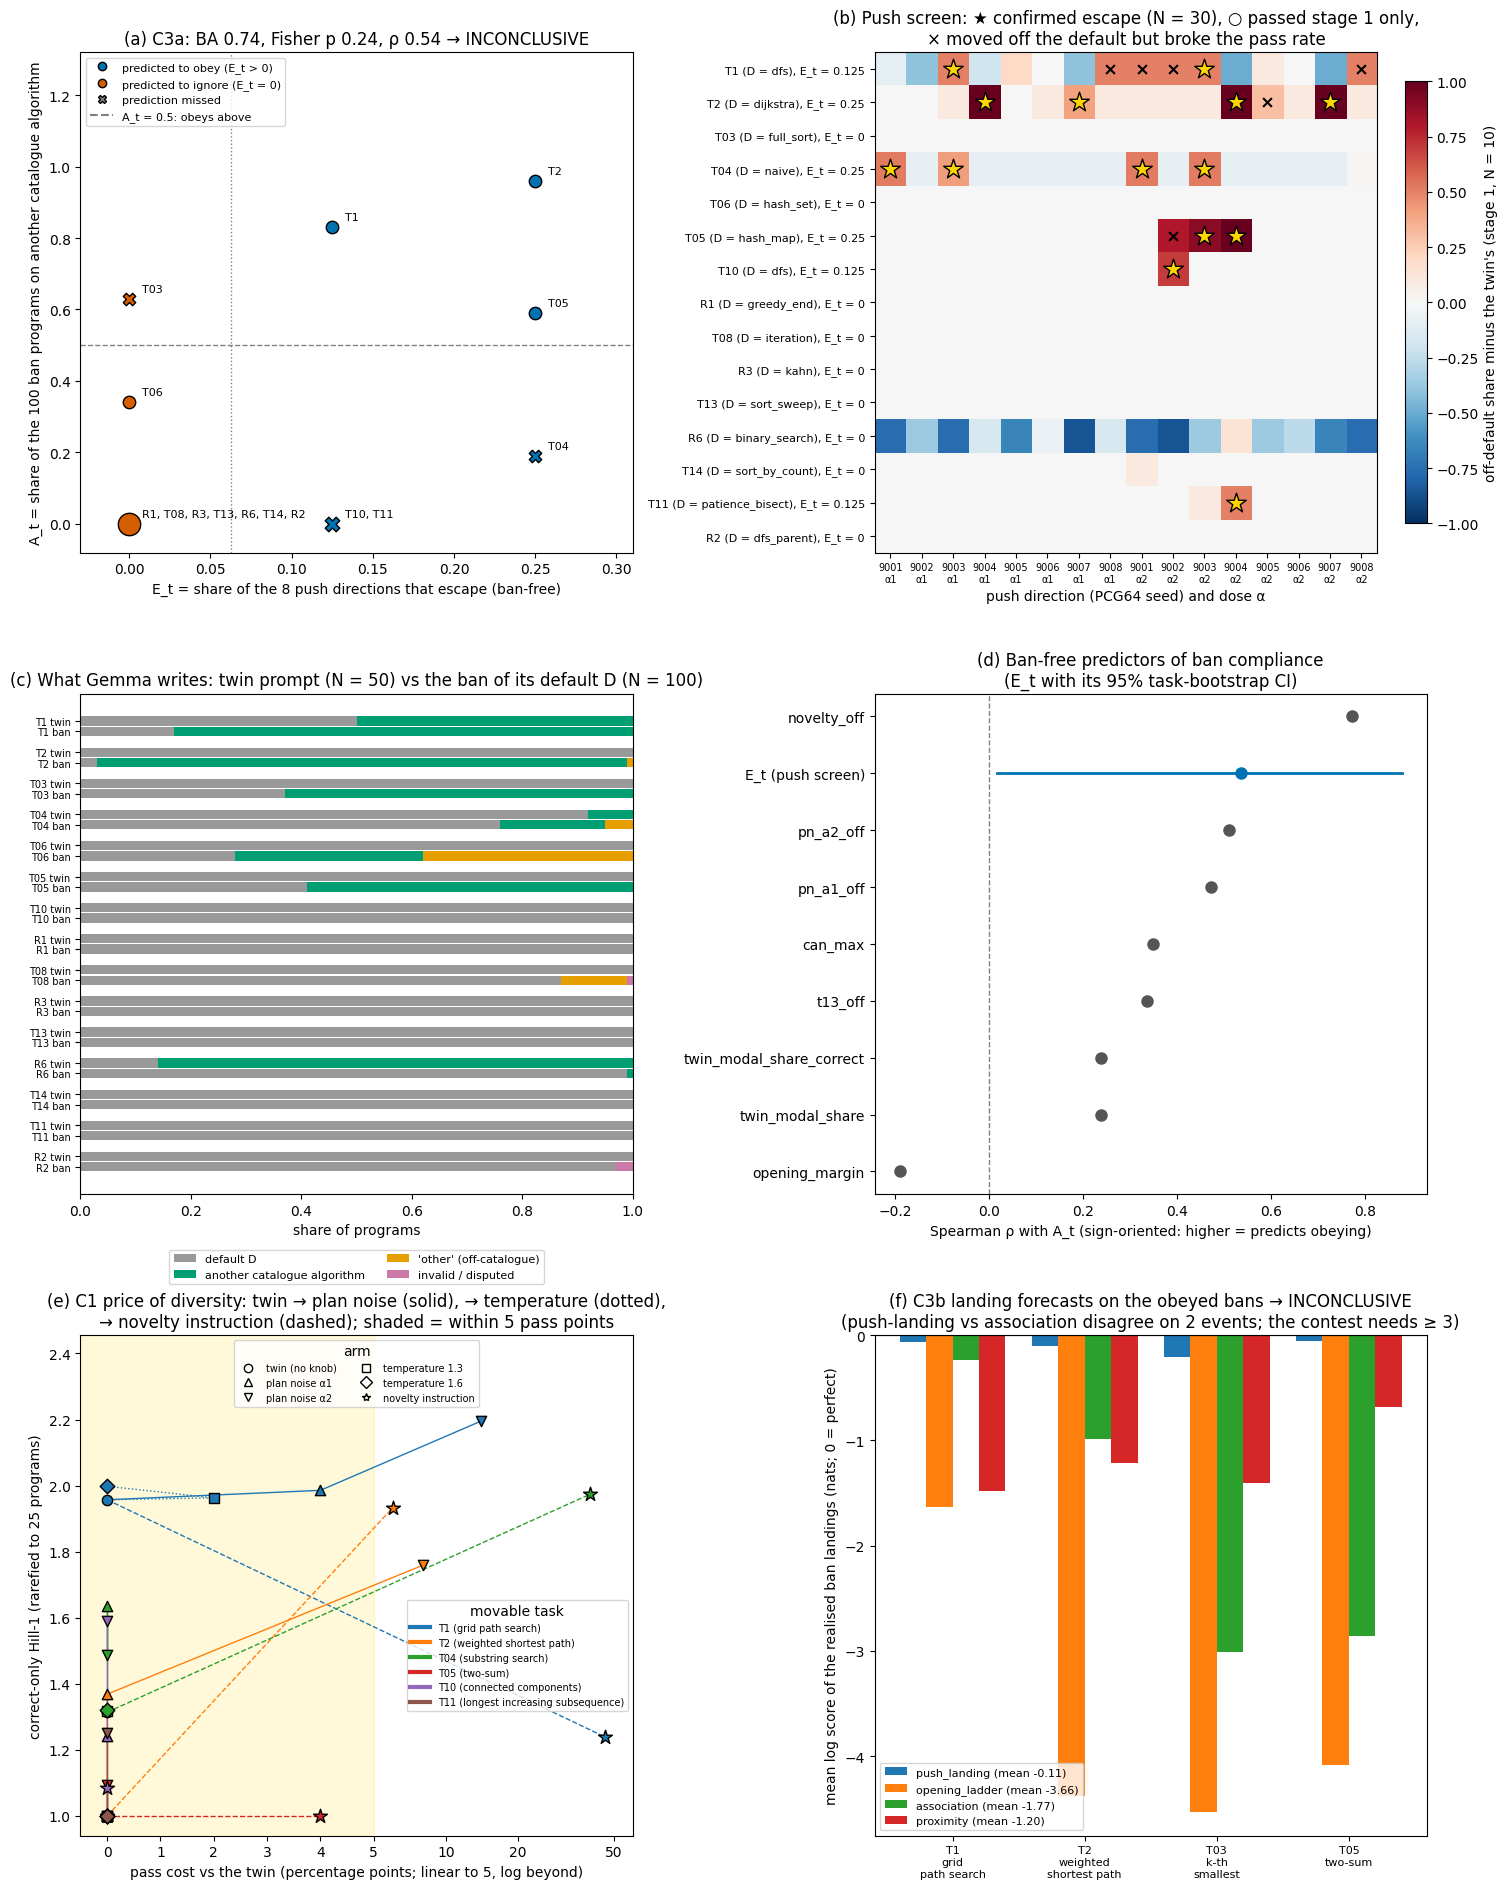

In [23]:
# Six panels drawn from the values computed in this notebook (nothing here is read from the reported results).
COL = {1: "#0072B2", 0: "#D55E00"}  # predicted to obey (movable) / predicted to ignore (immovable)
fig, axs = plt.subplots(3, 2, figsize=(15, 19))

# (a) the C3a test; tasks that share a point are drawn once and labelled together
ax = axs[0, 0]
groups = collections.defaultdict(list)
for t in tasks:
    groups[(E[t], At[t])].append(t)
for (x, y), ts in groups.items():
    pred_c, obs_c = int(mv[ts[0]]), int(y >= COMPLY_THRESH)
    ax.scatter(x, y, s=80 + 30 * (len(ts) - 1), color=COL[pred_c], marker="o" if pred_c == obs_c else "X",
               edgecolor="black", zorder=3)
    ax.annotate(", ".join(ts), (x, y), textcoords="offset points", xytext=(9, 5), fontsize=8)
ax.axhline(COMPLY_THRESH, color="grey", ls="--", lw=1)
ax.axvline(1 / 16, color="grey", ls=":", lw=1)
ax.set_xlim(-0.03, 0.31)
ax.set_ylim(-0.08, 1.32)
ax.set_xlabel("E_t = share of the 8 push directions that escape (ban-free)")
ax.set_ylabel("A_t = share of the 100 ban programs on another catalogue algorithm")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COL[1], mec="black", label="predicted to obey (E_t > 0)"),
                   plt.Line2D([], [], marker="o", ls="", color=COL[0], mec="black", label="predicted to ignore (E_t = 0)"),
                   plt.Line2D([], [], marker="X", ls="", color="grey", mec="black", label="prediction missed"),
                   plt.Line2D([], [], color="grey", ls="--", label="A_t = 0.5: obeys above")],
          loc="upper left", fontsize=8)
ax.set_title(f"(a) C3a: BA {primary['balanced_accuracy']['BA']:.2f}, Fisher p {primary['fisher']['p_two_sided']:.2f}, "
             f"ρ {primary['spearman']['rho']:.2f} → {primary['verdict']}")

# (b) the push screen: stage-1 excess off-default share for every task x (direction, alpha) cell
ax = axs[0, 1]
cells = [f"{s}_a{a}" for a in (1, 2) for s in ESCAPE_SEEDS]
M = np.array([[pre["tasks"][t]["stage1_cells"][c]["excess"] for c in cells] for t in tasks])
im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i, t in enumerate(tasks):
    for j, c in enumerate(cells):
        st1, cf = pre["tasks"][t]["stage1_cells"][c], pre["tasks"][t]["confirm_cells"].get(c, {})
        if cf.get("confirmed"):
            ax.scatter(j, i, marker="*", s=220, color="gold", edgecolor="black", zorder=3)
        elif st1["stage1_pass"]:
            ax.scatter(j, i, marker="o", s=70, facecolor="none", edgecolor="black", lw=1.5, zorder=3)
        elif st1["excess"] >= ESCAPE_EXCESS:
            ax.scatter(j, i, marker="x", s=40, color="black", zorder=3)
ax.set_xlim(-0.5, len(cells) - 0.5)
ax.set_ylim(len(tasks) - 0.5, -0.5)
ax.set_xticks(range(len(cells)))
ax.set_xticklabels([f"{c[:4]}\nα{c[-1]}" for c in cells], fontsize=7)
ax.set_yticks(range(len(tasks)))
ax.set_yticklabels([f"{t} (D = {pre['tasks'][t]['D']}), E_t = {E[t]:g}" for t in tasks], fontsize=8)
ax.set_xlabel("push direction (PCG64 seed) and dose α")
fig.colorbar(im, ax=ax, fraction=0.04, label="off-default share minus the twin's (stage 1, N = 10)")
ax.set_title("(b) Push screen: ★ confirmed escape (N = 30), ○ passed stage 1 only,\n"
             "× moved off the default but broke the pass rate")

# (c) composition of the 50 twin programs vs the 100 ban programs per task
ax = axs[1, 0]
parts = {"default D": "#999999", "another catalogue algorithm": "#009E73", "'other' (off-catalogue)": "#E69F00",
         "invalid / disputed": "#CC79A7"}
ys, ylabels, shares = [], [], []
for i, t in enumerate(tasks):
    D = pre["tasks"][t]["D"]
    twin_comp = next(ex for ex in task_events if ex["metadata_task"] == t)["metadata_c1_arms"]["twin"]["attempt_comp"]
    for j, (arm, comp) in enumerate((("twin", twin_comp), ("ban", ot[t]["composition"]))):
        n = sum(comp.values())
        d, o = comp.get(D, 0) / n, comp.get("other", 0) / n
        bad = (comp.get("invalid", 0) + comp.get("disputed", 0)) / n
        shares.append([d, 1 - d - o - bad, o, bad])
        ys.append(3 * i + j)
        ylabels.append(f"{t} {arm}")
shares = np.clip(np.array(shares), 0, 1)
left = np.zeros(len(shares))
for k, (name, col) in enumerate(parts.items()):
    ax.barh(ys, shares[:, k], left=left, color=col, label=name, height=0.9)
    left += shares[:, k]
ax.set_yticks(ys)
ax.set_yticklabels(ylabels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of programs")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8)
ax.set_title("(c) What Gemma writes: twin prompt (N = 50) vs the ban of its default D (N = 100)")

# (d) rival predictors: Spearman rho with A_t, sign-oriented
ax = axs[1, 1]
fr = [("E_t (push screen)", primary["spearman"]["rho"], primary["bootstrap"]["rho_ci95"])]
fr += [(k, v["rho_rival_sign_oriented"], None) for k, v in rv.items() if v.get("rho_rival_sign_oriented") is not None]
fr.sort(key=lambda r: r[1])
for i, (nm, r, ci) in enumerate(fr):
    c = COL[1] if nm.startswith("E_t") else "#555555"
    ax.plot([r], [i], "o", color=c, ms=8)
    if ci:
        ax.plot(ci, [i, i], "-", color=c, lw=2)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(range(len(fr)))
ax.set_yticklabels([r[0] for r in fr])
ax.set_xlabel("Spearman ρ with A_t (sign-oriented: higher = predicts obeying)")
ax.set_title("(d) Ban-free predictors of ban compliance\n(E_t with its 95% task-bootstrap CI)")

# (e) C1: correct-only Hill-1 vs pass cost per arm on the movable tasks (x linear up to 5 points, log beyond)
ax = axs[2, 0]
mk = {"twin": "o", "pn_a1": "^", "pn_a2": "v", "t13": "s", "t16": "D", "novelty": "*"}
arm_name = {"twin": "twin (no knob)", "pn_a1": "plan noise α1", "pn_a2": "plan noise α2", "t13": "temperature 1.3",
            "t16": "temperature 1.6", "novelty": "novelty instruction"}
for k, t in enumerate(mov):
    arms_t, col = c1_res["per_task"][t]["arms"], plt.cm.tab10(k)
    for chain, ls in ((("twin", "pn_a1", "pn_a2"), "-"), (("twin", "t13", "t16"), ":"), (("twin", "novelty"), "--")):
        pts = [(arms_t[a]["pass_cost_points"], arms_t[a]["hill1_rarefied25"]) for a in chain
               if a in arms_t and arms_t[a]["hill1_rarefied25"] is not None]
        if len(pts) >= 2:
            ax.plot(*zip(*pts), ls=ls, color=col, lw=1)
    for a, v in arms_t.items():
        if v["hill1_rarefied25"] is not None:
            ax.scatter(v["pass_cost_points"], v["hill1_rarefied25"], marker=mk[a], s=110 if a == "novelty" else 55,
                       color=col, edgecolor="black", zorder=3)
ax.set_xscale("symlog", linthresh=5, linscale=1.0)
ax.set_xlim(-0.5, 60)
ax.set_xticks([0, 1, 2, 3, 4, 5, 10, 20, 50])
ax.set_xticklabels(["0", "1", "2", "3", "4", "5", "10", "20", "50"])
ax.axvspan(-0.5, 5, color="gold", alpha=0.15)
lo, hi = ax.get_ylim()
ax.set_ylim(lo, hi + 0.2)  # headroom for the arm legend
leg = ax.legend(handles=[plt.Line2D([], [], marker=mk[a], ls="", color="white", mec="black", label=arm_name[a])
                         for a in mk], loc="upper center", ncol=2, fontsize=7, title="arm")
ax.add_artist(leg)
ax.legend(handles=[plt.Line2D([], [], color=plt.cm.tab10(k), lw=3, label=f"{t} ({TASK_TITLES[t]})")
                   for k, t in enumerate(mov)], loc="center right", bbox_to_anchor=(1.0, 0.36), fontsize=7,
          title="movable task")
ax.set_xlabel("pass cost vs the twin (percentage points; linear to 5, log beyond)")
ax.set_ylabel("correct-only Hill-1 (rarefied to 25 programs)")
ax.set_title("(e) C1 price of diversity: twin → plan noise (solid), → temperature (dotted),\n"
             "→ novelty instruction (dashed); shaded = within 5 pass points")

# (f) C3b: mean log score of each committed landing forecast per obeyed ban
ax = axs[2, 1]
fc = ["push_landing", "opening_ladder", "association", "proximity"]
evs = list(c3b_res["per_event"])
w = 0.2
for k, nm in enumerate(fc):
    vals = [c3b_res["per_event"][t][nm]["log_score"] for t in evs]
    ax.bar(np.arange(len(evs)) + (k - 1.5) * w, vals, width=w,
           label=f"{nm} (mean {c3b_res['summary'][nm]['mean_log_score']:.2f})")
ax.set_xticks(range(len(evs)))
ax.set_xticklabels([f"{t}\n{TASK_TITLES[t].replace(' ', chr(10), 1)}" for t in evs], fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("mean log score of the realised ban landings (nats; 0 = perfect)")
ax.legend(fontsize=8, loc="lower left")
ax.set_title(f"(f) C3b landing forecasts on the obeyed bans → {c3b_res['verdict']}\n"
             f"(push-landing vs association disagree on {c3b_res['contest']['push_landing']['n_disagreeing']} events; "
             f"the contest needs ≥ 3)")

fig.tight_layout()
plt.show()

## Takeaways

- **Movability is related to ban compliance, but it does not pass the bar.** On the held-out family the screen points the right way (Spearman ρ ≈ 0.54, one-sided p ≈ 0.025). It still misses the pre-registered criteria: BA 0.74 with a CI down to 0.40, and Fisher p 0.24. Two movable tasks (T10, T11) ignore their ban completely, and T03 obeys without being movable.
- **Asking in words is the stronger baseline.** The novelty instruction's off-default share tracks compliance better (ρ ≈ 0.77) than pushing the activations.
- **Temperature is not the creativity knob here.** Temperature 1.3/1.6 leaves Gemma's algorithm choice unchanged. Plan noise in the residual stream diversifies the algorithm at ≤ 5 pass points (C1). The novelty audit (reported, not re-run here) found no novel algorithm among the 34 correct programs labelled 'other'.
- **The labeller is part of the measurement.** T2's "obeys" outcome is mostly array-based Dijkstra read as Bellman-Ford. Relabelled, T2 avoidance falls from 0.96 to 0.11, and C3a stays INCONCLUSIVE either way.